进入 21 世纪，生命科学特别是基因科技已经广泛而且深刻影响到每个人的健康生活，于此同时，科学家们借助基因科技史无前例的用一种全新的视角解读生命和探究疾病本质。人工智能（AI）能够处理分析海量医疗健康数据，通过认知分析获取洞察，服务于政府、健康医疗机构、制药企业及患者，实现个性化，可以循证的智慧医疗，推动创新，实现价值。

心血管病、糖尿病等慢性疾病，每年导致的死亡人数占总死亡人数的 80%，每年用于慢病医疗费用占中国公共医疗卫生支出的比例超过 13%。作为一种常见慢性疾病，糖尿病目前无法根治，但却能通过科学有效的干预、预防和治疗，来降低发病率和提高患者的生活质量。阿里云联合青梧桐健康科技有限公司主办天池精准医疗大赛——人工智能辅助糖尿病遗传风险预测，希望用人工智能的方法和思想处理、分析、解读和应用糖尿病相关大数据，让参赛选手设计高精度，高效，且解释性强的算法来挑战糖尿病精准预测这一科学难题，为学术界和精准医疗提供有力的技术支撑，帮助我们攻克糖尿病。


In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
from scipy.stats import norm
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, cross_val_score, RandomizedSearchCV, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

plt.rcParams["font.sans-serif"] = ["Songti SC"]
plt.rcParams["axes.unicode_minus"] = False

train_data = pd.read_csv("./data/d_train_20180102.csv", encoding="utf-8")
a_data = pd.read_csv("./data/d_test_A_20180102.csv", encoding="utf-8")
a_labels = pd.read_csv("./data/d_answer_a_20180128.csv", encoding="utf-8").iloc[:, 0]
assert len(a_data) == len(a_labels)
a_data["血糖"] = a_labels.to_numpy()
raw_data = pd.concat([train_data, a_data], ignore_index=True)
assert raw_data["id"].is_unique and raw_data["血糖"].notna().all()

# 保留上次修复后的开发划分，方便同口径比较；B 的特征和答案到最后才读取。
train_raw_data, validation_raw_data = train_test_split(raw_data, test_size=0.3, random_state=23)
assert set(train_raw_data["id"]).isdisjoint(validation_raw_data["id"])
data = train_raw_data.copy()
validation_data = validation_raw_data.copy()
cv = KFold(n_splits=5, shuffle=True, random_state=23)
model_registry = {}
representation_reports = {}
development_results = []
SEARCH_N_JOBS = 2
print("完整训练/开发验证样本数:", len(data), len(validation_data))
data.head()

完整训练/开发验证样本数: 4649 1993


,id,性别,年龄,体检日期,*天门冬氨酸氨基转换酶,*丙氨酸氨基转换酶,*碱性磷酸酶,*r-谷氨酰基转换酶,*总蛋白,白蛋白,...,血小板计数,血小板平均体积,血小板体积分布宽度,血小板比积,中性粒细胞%,淋巴细胞%,单核细胞%,嗜酸细胞%,嗜碱细胞%,血糖
5640,5731,女,55,10/10/2017,33.54,24.94,97.60,19.16,78.50,43.10,...,220.0,12.2,16.3,0.27,55.0,36.9,6.8,0.7,0.6,6.37
3388,3445,男,69,22/09/2017,30.36,19.41,73.36,27.14,76.74,42.73,...,220.0,11.1,13.6,0.24,63.8,25.2,9.5,1.0,0.5,4.75
5631,5722,女,36,10/10/2017,22.08,4.62,51.76,16.76,78.62,45.23,...,226.0,10.4,11.9,0.24,57.7,35.5,5.3,0.9,0.6,5.58
6592,6719,女,52,19/10/2017,22.40,18.26,94.34,19.88,81.36,46.57,...,223.0,11.1,14.3,0.25,73.3,21.7,3.5,1.2,0.3,5.32
3061,3115,女,52,26/10/2017,NaN,NaN,NaN,NaN,NaN,NaN,...,305.0,10.9,14.3,0.33,55.5,33.4,8.1,2.6,0.4,5.42


# 训练集数据概况与评估边界

探索、填补统计、相关性分析、特征消融与参数搜索只使用训练数据。训练集 4649 条、开发验证集 1993 条，均不因缺失或极端特征值而删行。

开发验证集用于比较模型类别，不再称为最终测试集。B 集只在模型类别、特征处理与参数冻结后，对全部已冻结算法作外部对照；B 此前已经用于研究，所以不能声称是从未触碰的盲测。反复根据 B 调整方案会使它继续变成开发数据。

In [3]:
data.describe()

,id,年龄,*天门冬氨酸氨基转换酶,*丙氨酸氨基转换酶,*碱性磷酸酶,*r-谷氨酰基转换酶,*总蛋白,白蛋白,*球蛋白,白球比例,...,血小板计数,血小板平均体积,血小板体积分布宽度,血小板比积,中性粒细胞%,淋巴细胞%,单核细胞%,嗜酸细胞%,嗜碱细胞%,血糖
count,4649.000000,4649.000000,3675.000000,3675.000000,3675.000000,3675.000000,3675.000000,3675.000000,3675.000000,3675.000000,...,4636.000000,4631.000000,4631.000000,4631.000000,4636.000000,4636.000000,4636.000000,4636.000000,4636.000000,4649.000000
mean,3375.520327,45.718004,26.734626,27.458754,87.321148,38.642680,76.861238,45.892022,30.969216,1.503940,...,252.160483,10.599633,13.363593,0.265646,56.775000,33.766372,6.833909,2.022692,0.604314,5.626855
std,1951.622417,13.022185,12.170923,21.262029,25.433540,40.801011,4.034765,2.598614,3.574473,0.223325,...,60.060021,1.014194,2.227876,0.061318,7.847274,7.304655,1.558555,1.698116,0.292994,1.474255
min,1.000000,3.000000,10.040000,0.120000,22.980000,6.360000,57.320000,29.540000,7.060000,0.520000,...,37.000000,7.000000,8.000000,0.042000,21.100000,9.700000,3.100000,0.000000,0.000000,3.070000
25%,1685.000000,35.000000,20.240000,15.120000,69.685000,17.930000,74.285000,44.230000,28.590000,1.360000,...,212.000000,10.000000,11.700000,0.224000,51.575000,28.800000,5.800000,0.900000,0.400000,4.940000
50%,3392.000000,45.000000,23.910000,21.400000,84.460000,26.300000,76.720000,45.850000,30.820000,1.490000,...,247.500000,10.600000,13.000000,0.260000,56.800000,33.600000,6.700000,1.600000,0.600000,5.310000
75%,5048.000000,55.000000,29.335000,32.175000,100.395000,43.720000,79.650000,47.620000,33.210000,1.630000,...,287.250000,11.200000,14.700000,0.300000,62.100000,38.600000,7.700000,2.500000,0.700000,5.770000
max,6768.000000,93.000000,281.210000,388.000000,345.730000,736.990000,100.410000,54.080000,66.180000,7.120000,...,745.000000,15.200000,25.300000,0.710000,84.500000,73.600000,23.200000,19.100000,3.400000,38.430000


初始数据集的年龄分布直方图


频数:[   2.    6.  488. 1078. 1054. 1071.  623.  217.   91.   19.]
区间:[ 3. 12. 21. 30. 39. 48. 57. 66. 75. 84. 93.]


Text(0.5, 1.0, '初始数据集的年龄分布——直方图')

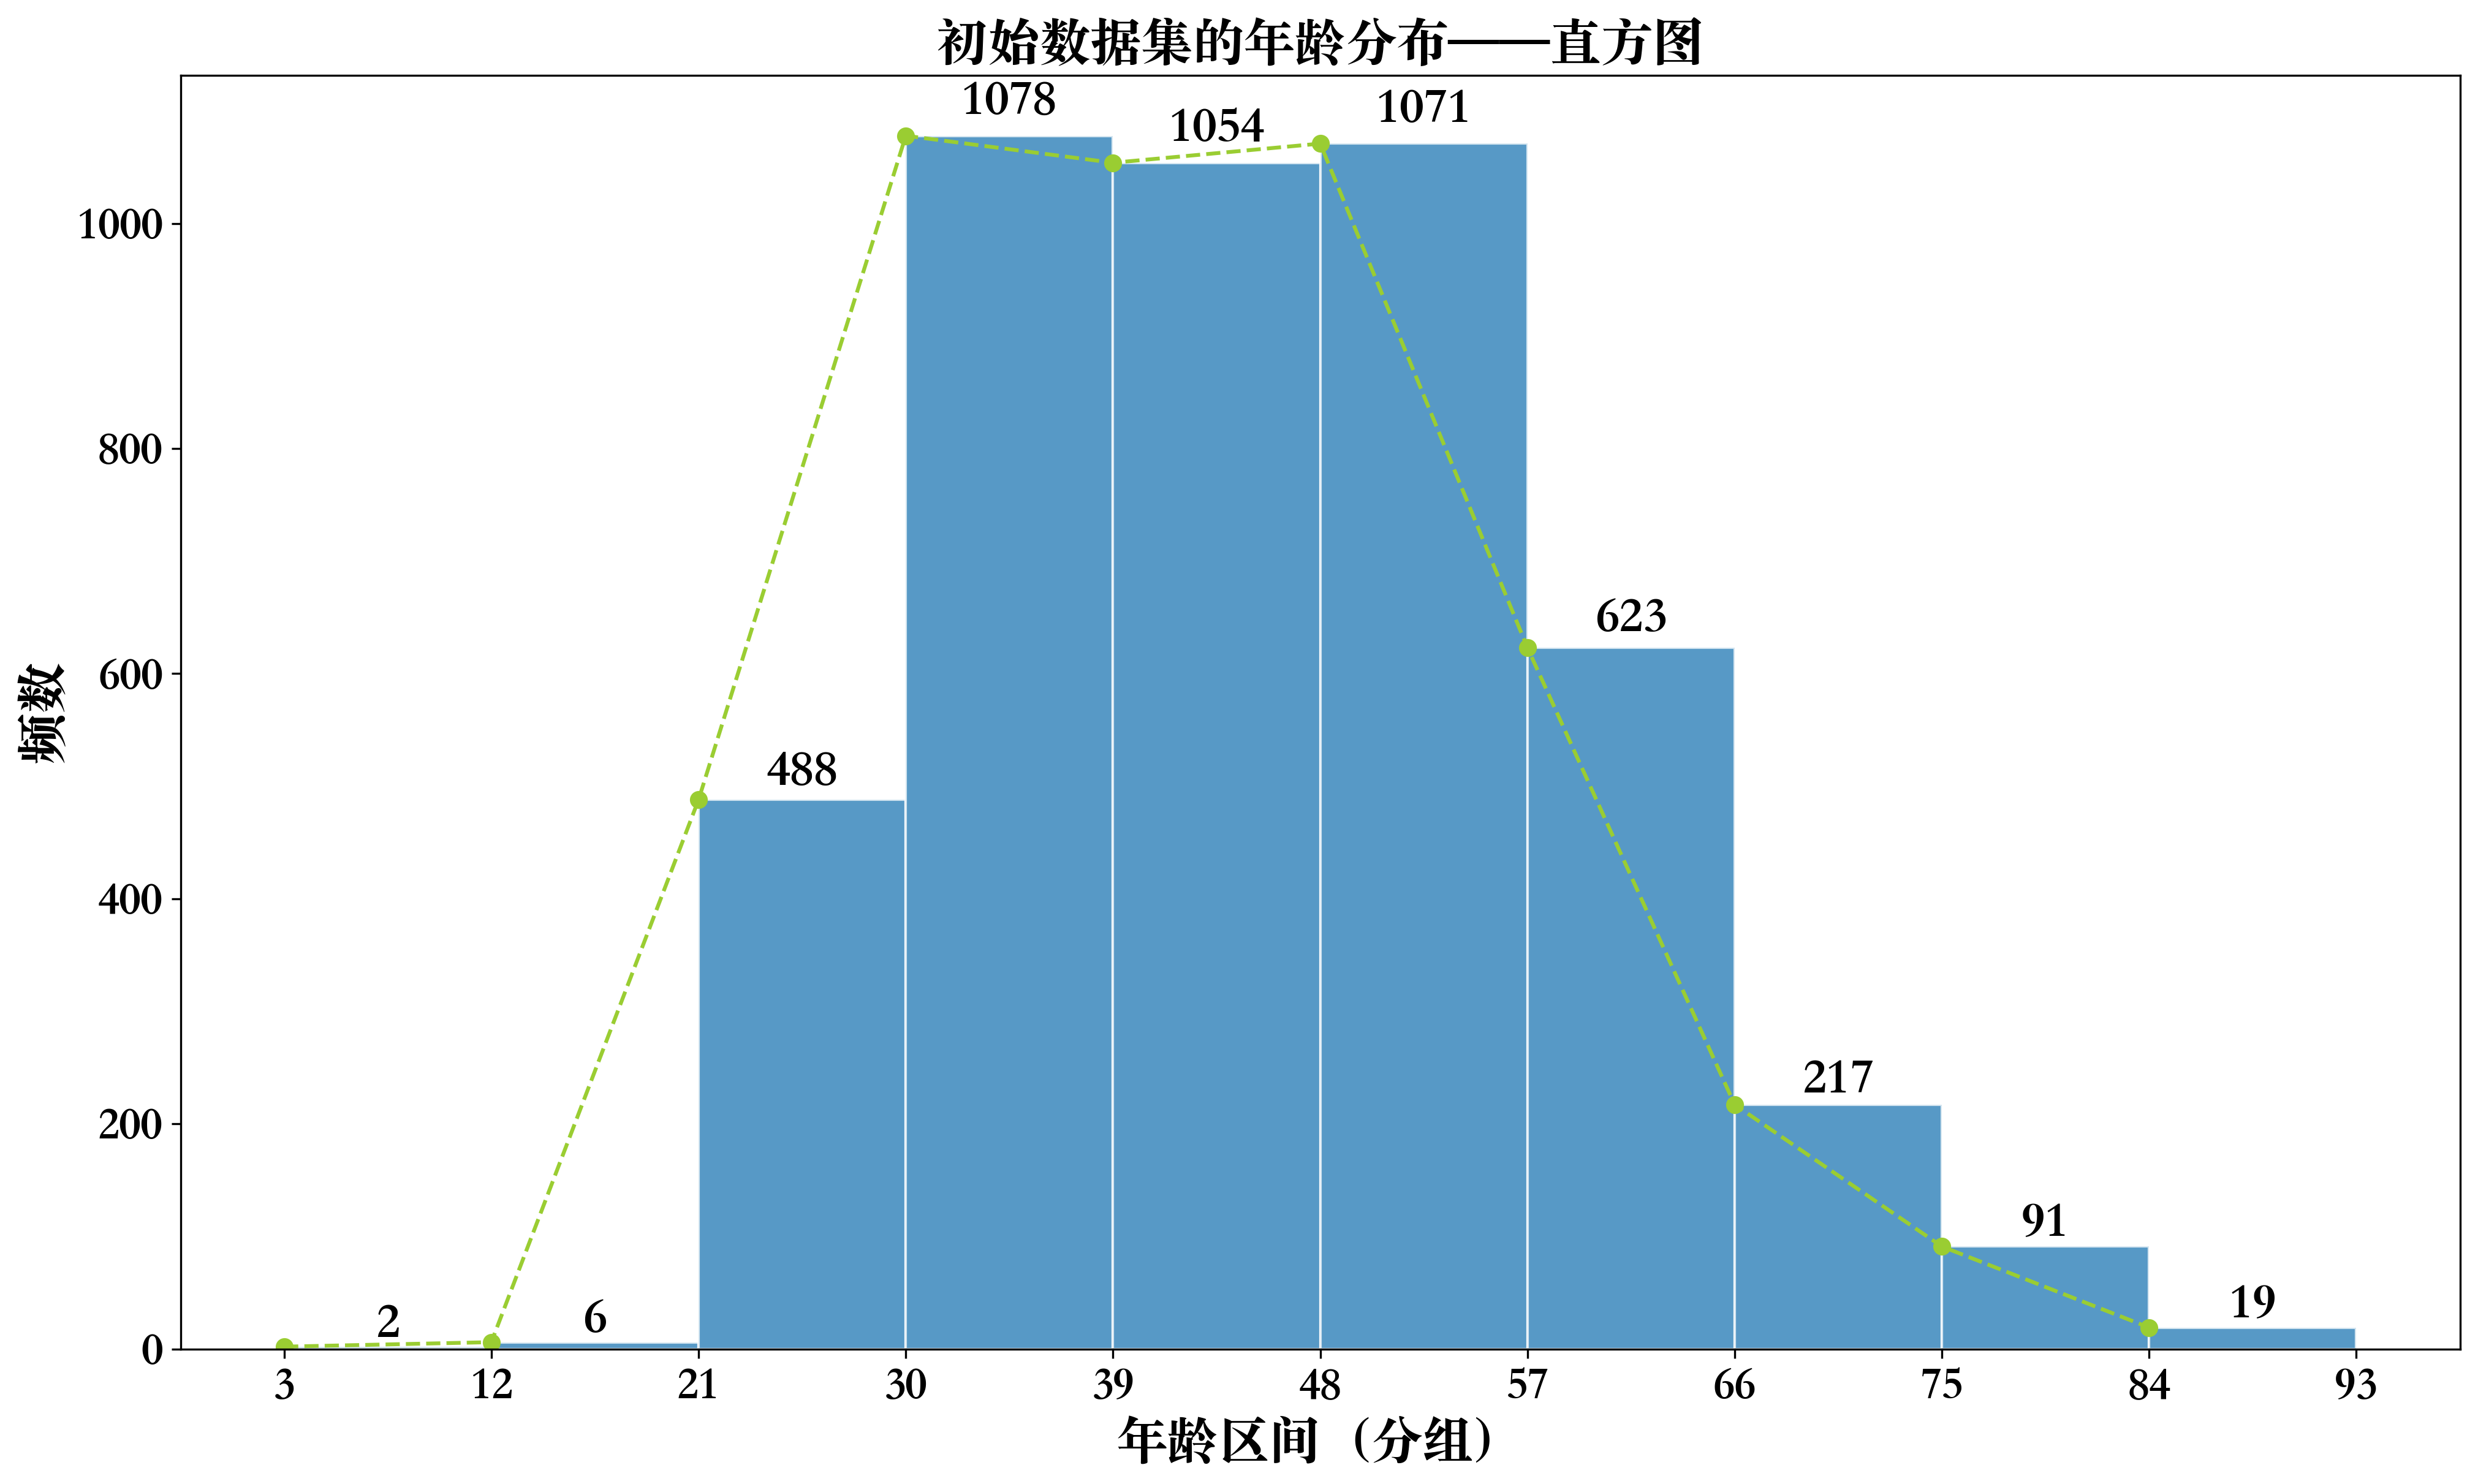

In [4]:
fig, ax = plt.subplots(figsize=(16, 9), dpi=300)

n, bins_num, patches = ax.hist(data["年龄"], bins=10, alpha=0.75, edgecolor="white")

ax.plot(bins_num[:10], n, marker="o", color="yellowgreen", linestyle="--")

for i in range(len(n)):
    plt.text(
        x=bins_num[i] + (bins_num[1] - bins_num[0]) / 2,
        y=n[i] * 1.01,
        s=str(int(n[i])),
        ha="center",
        va="bottom",
        fontsize=20,
    )

print("频数:{}\n区间:{}".format(n, bins_num))

min_age = data["年龄"].min()
max_age = data["年龄"].max()

t1 = np.linspace(min_age, max_age, num=11)

plt.xticks(t1)
plt.tick_params(labelsize=18)
plt.xlabel("年龄区间（分组）", fontdict={"weight": "normal", "size": 20})
plt.ylabel("频数", fontdict={"weight": "normal", "size": 20})
plt.title("初始数据集的年龄分布——直方图", fontdict={"weight": "normal", "size": 20})

初始数据集的血糖分布图


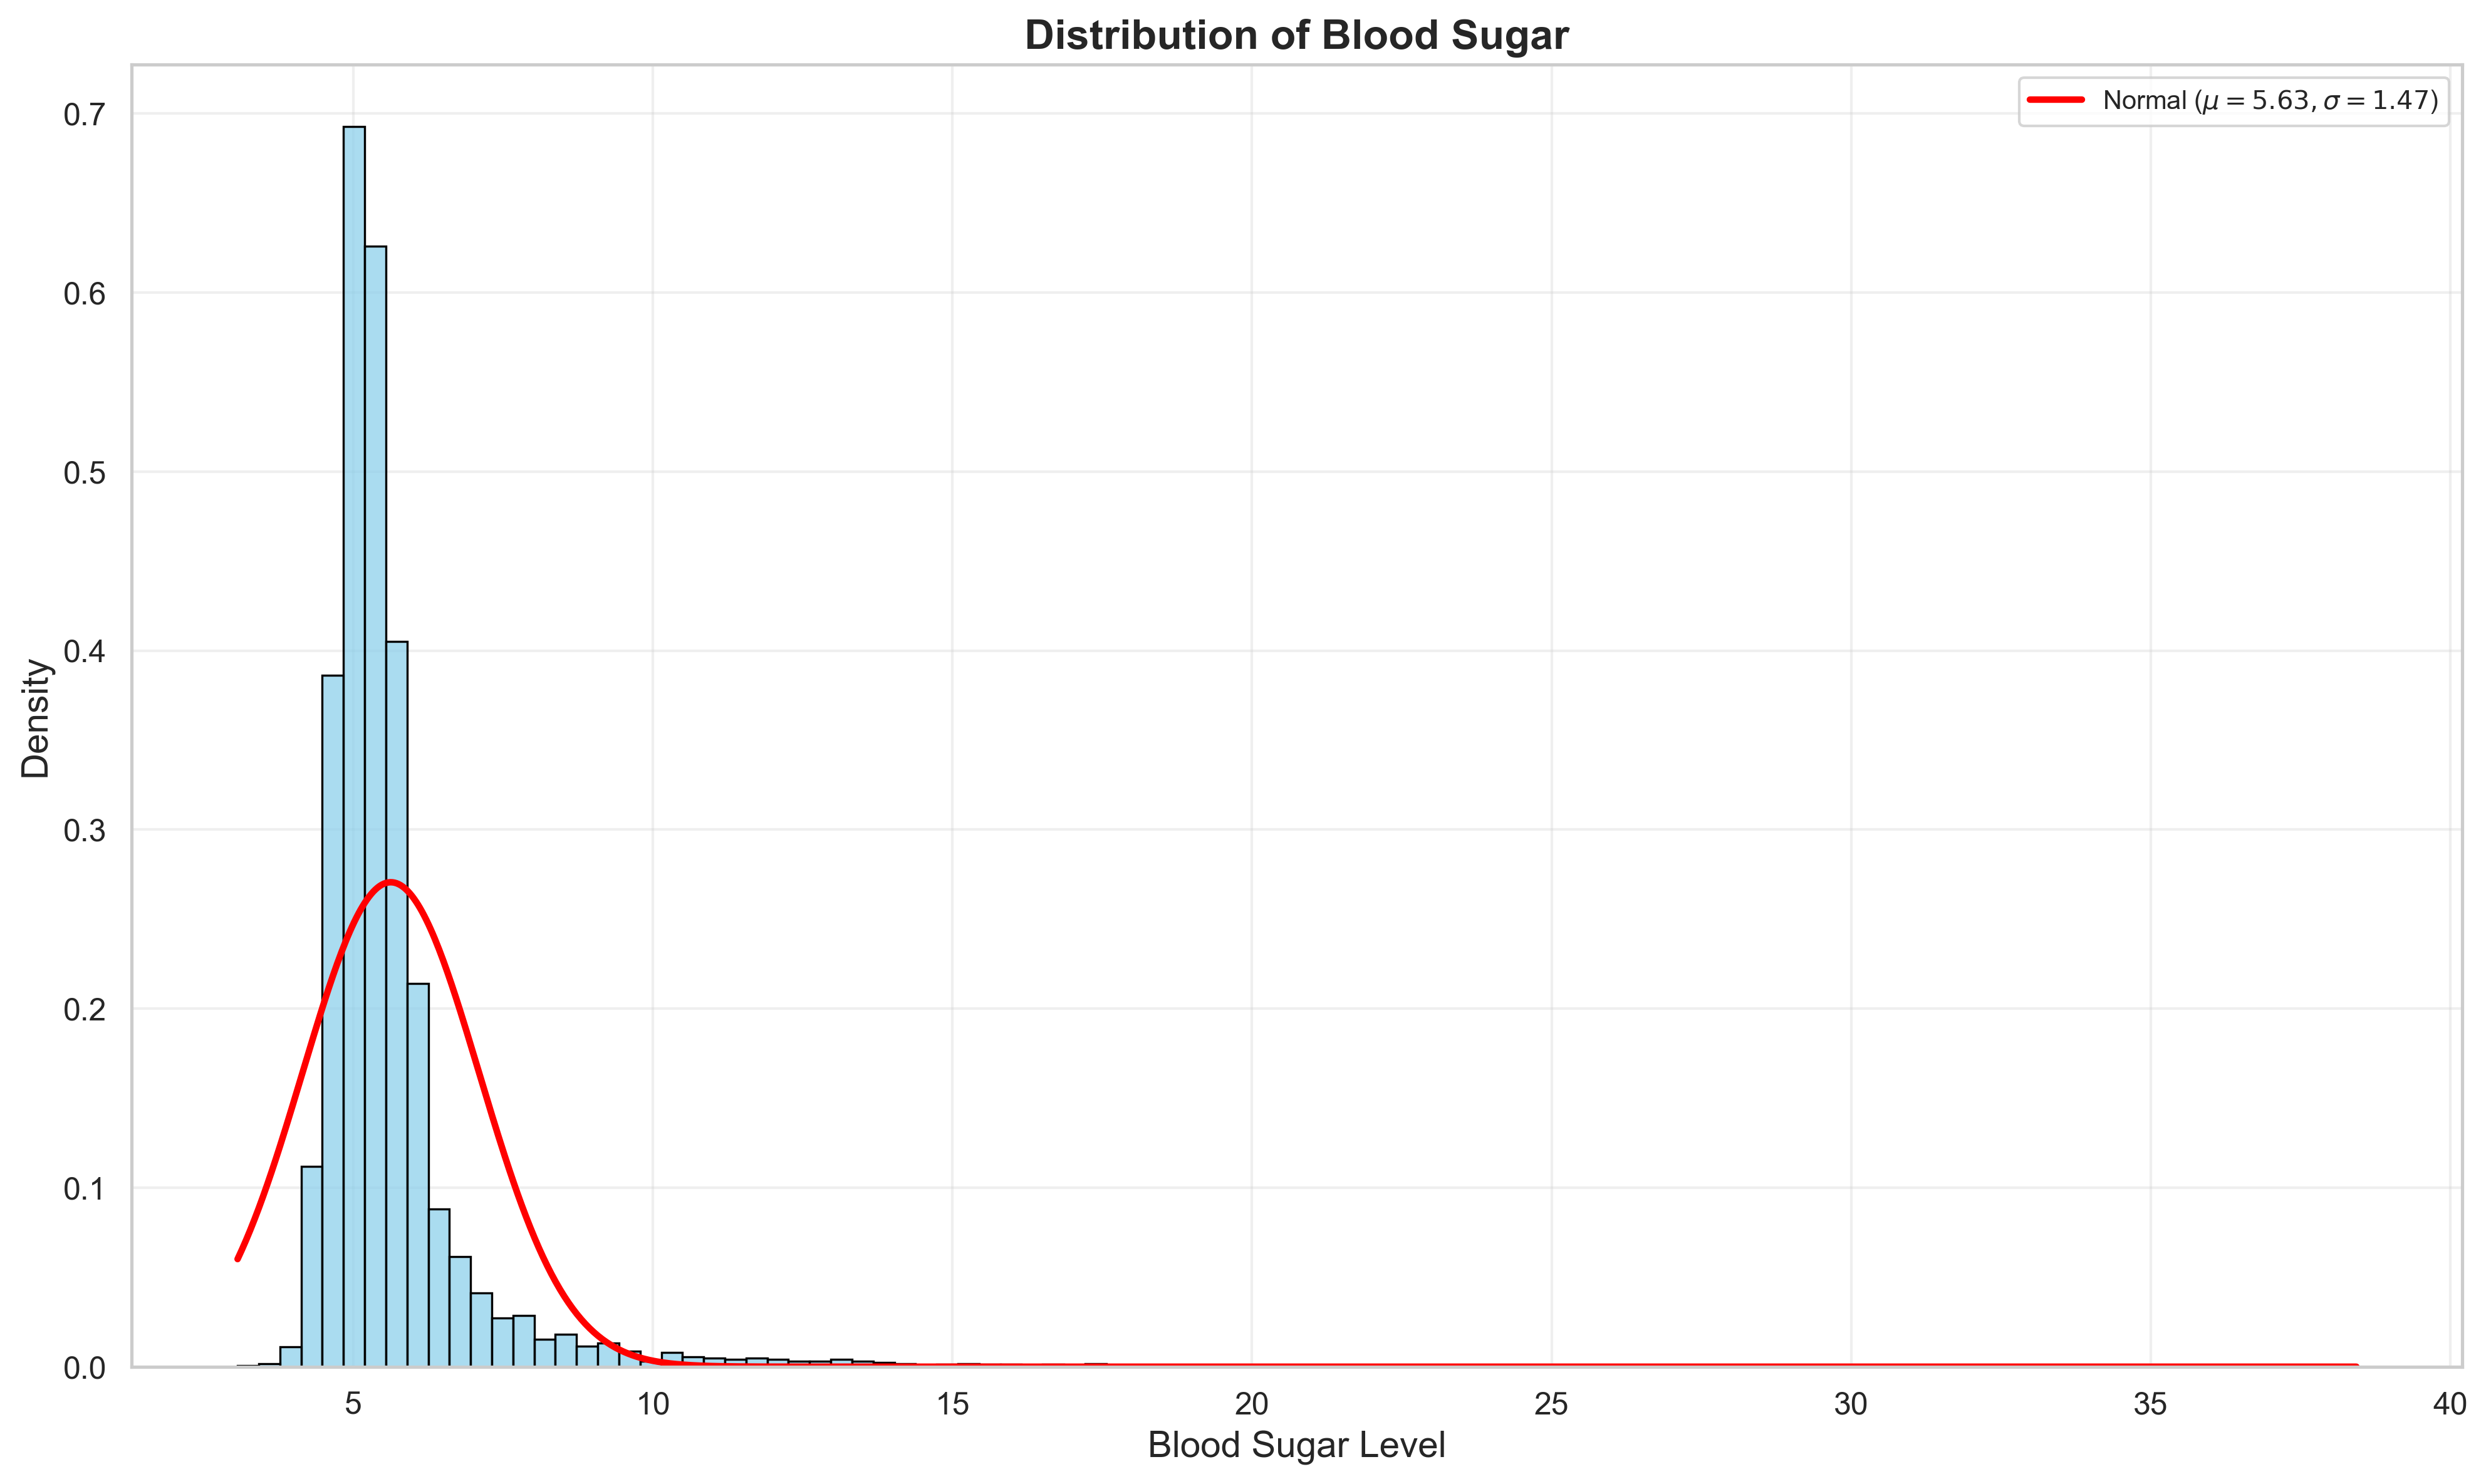

In [5]:
plt.figure(figsize=(16, 9), dpi=300)

sns.set_theme(style="whitegrid", palette="deep")

# 绘制直方图
sns.histplot(
    data=data,
    x="血糖",
    stat="density",
    bins=100,
    kde=False,
    color="skyblue",
    edgecolor="black",
    alpha=0.7,
)

# 计算正态分布参数
(mu, sigma) = norm.fit(data["血糖"])

# 绘制正态分布曲线
x = np.linspace(data["血糖"].min(), data["血糖"].max(), 1000)
p = norm.pdf(x, mu, sigma)
plt.plot(x, p, color="red", linewidth=2.5, label=fr"Normal ($\mu={mu:.2f}, \sigma={sigma:.2f}$)")

# 设置标题和坐标轴
plt.title("Distribution of Blood Sugar", fontsize=16, fontweight="bold")
plt.xlabel("Blood Sugar Level", fontsize=14)
plt.ylabel("Density", fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

# 图例
plt.legend(
    loc="upper right",
    fontsize=10,
    frameon=True,
    fancybox=True,
    framealpha=0.8,
)

# 网格透明度
plt.grid(alpha=0.3)

# 显示图表
plt.show()

初始数据集的数据缺失情况


In [6]:
# 统计每一列缺失值的百分比
missing_rate = (data.isnull().sum() / data.shape[0] * 100).sort_values(ascending=False)
# 将结果转换为dataframe
missing_rate_df = pd.DataFrame(missing_rate, columns=["Missing_Ratio(%)"])
missing_rate_df["Missing_Ratio(%)"] = missing_rate_df["Missing_Ratio(%)"].round(4)
# 重置索引，将列名作为一列
missing_rate_df = missing_rate_df.reset_index().rename(columns={"index": "col_name"})
missing_rate_df

,col_name,Missing_Ratio(%)
0,乙肝e抗原,76.7047
1,乙肝核心抗体,76.7047
2,乙肝e抗体,76.7047
3,乙肝表面抗体,76.7047
4,乙肝表面抗原,76.7047
5,尿素,23.1233
6,肌酐,23.1233
7,尿酸,23.1233
8,*总蛋白,20.9507
9,白蛋白,20.9507


Text(0.5, 0, '缺失比率')

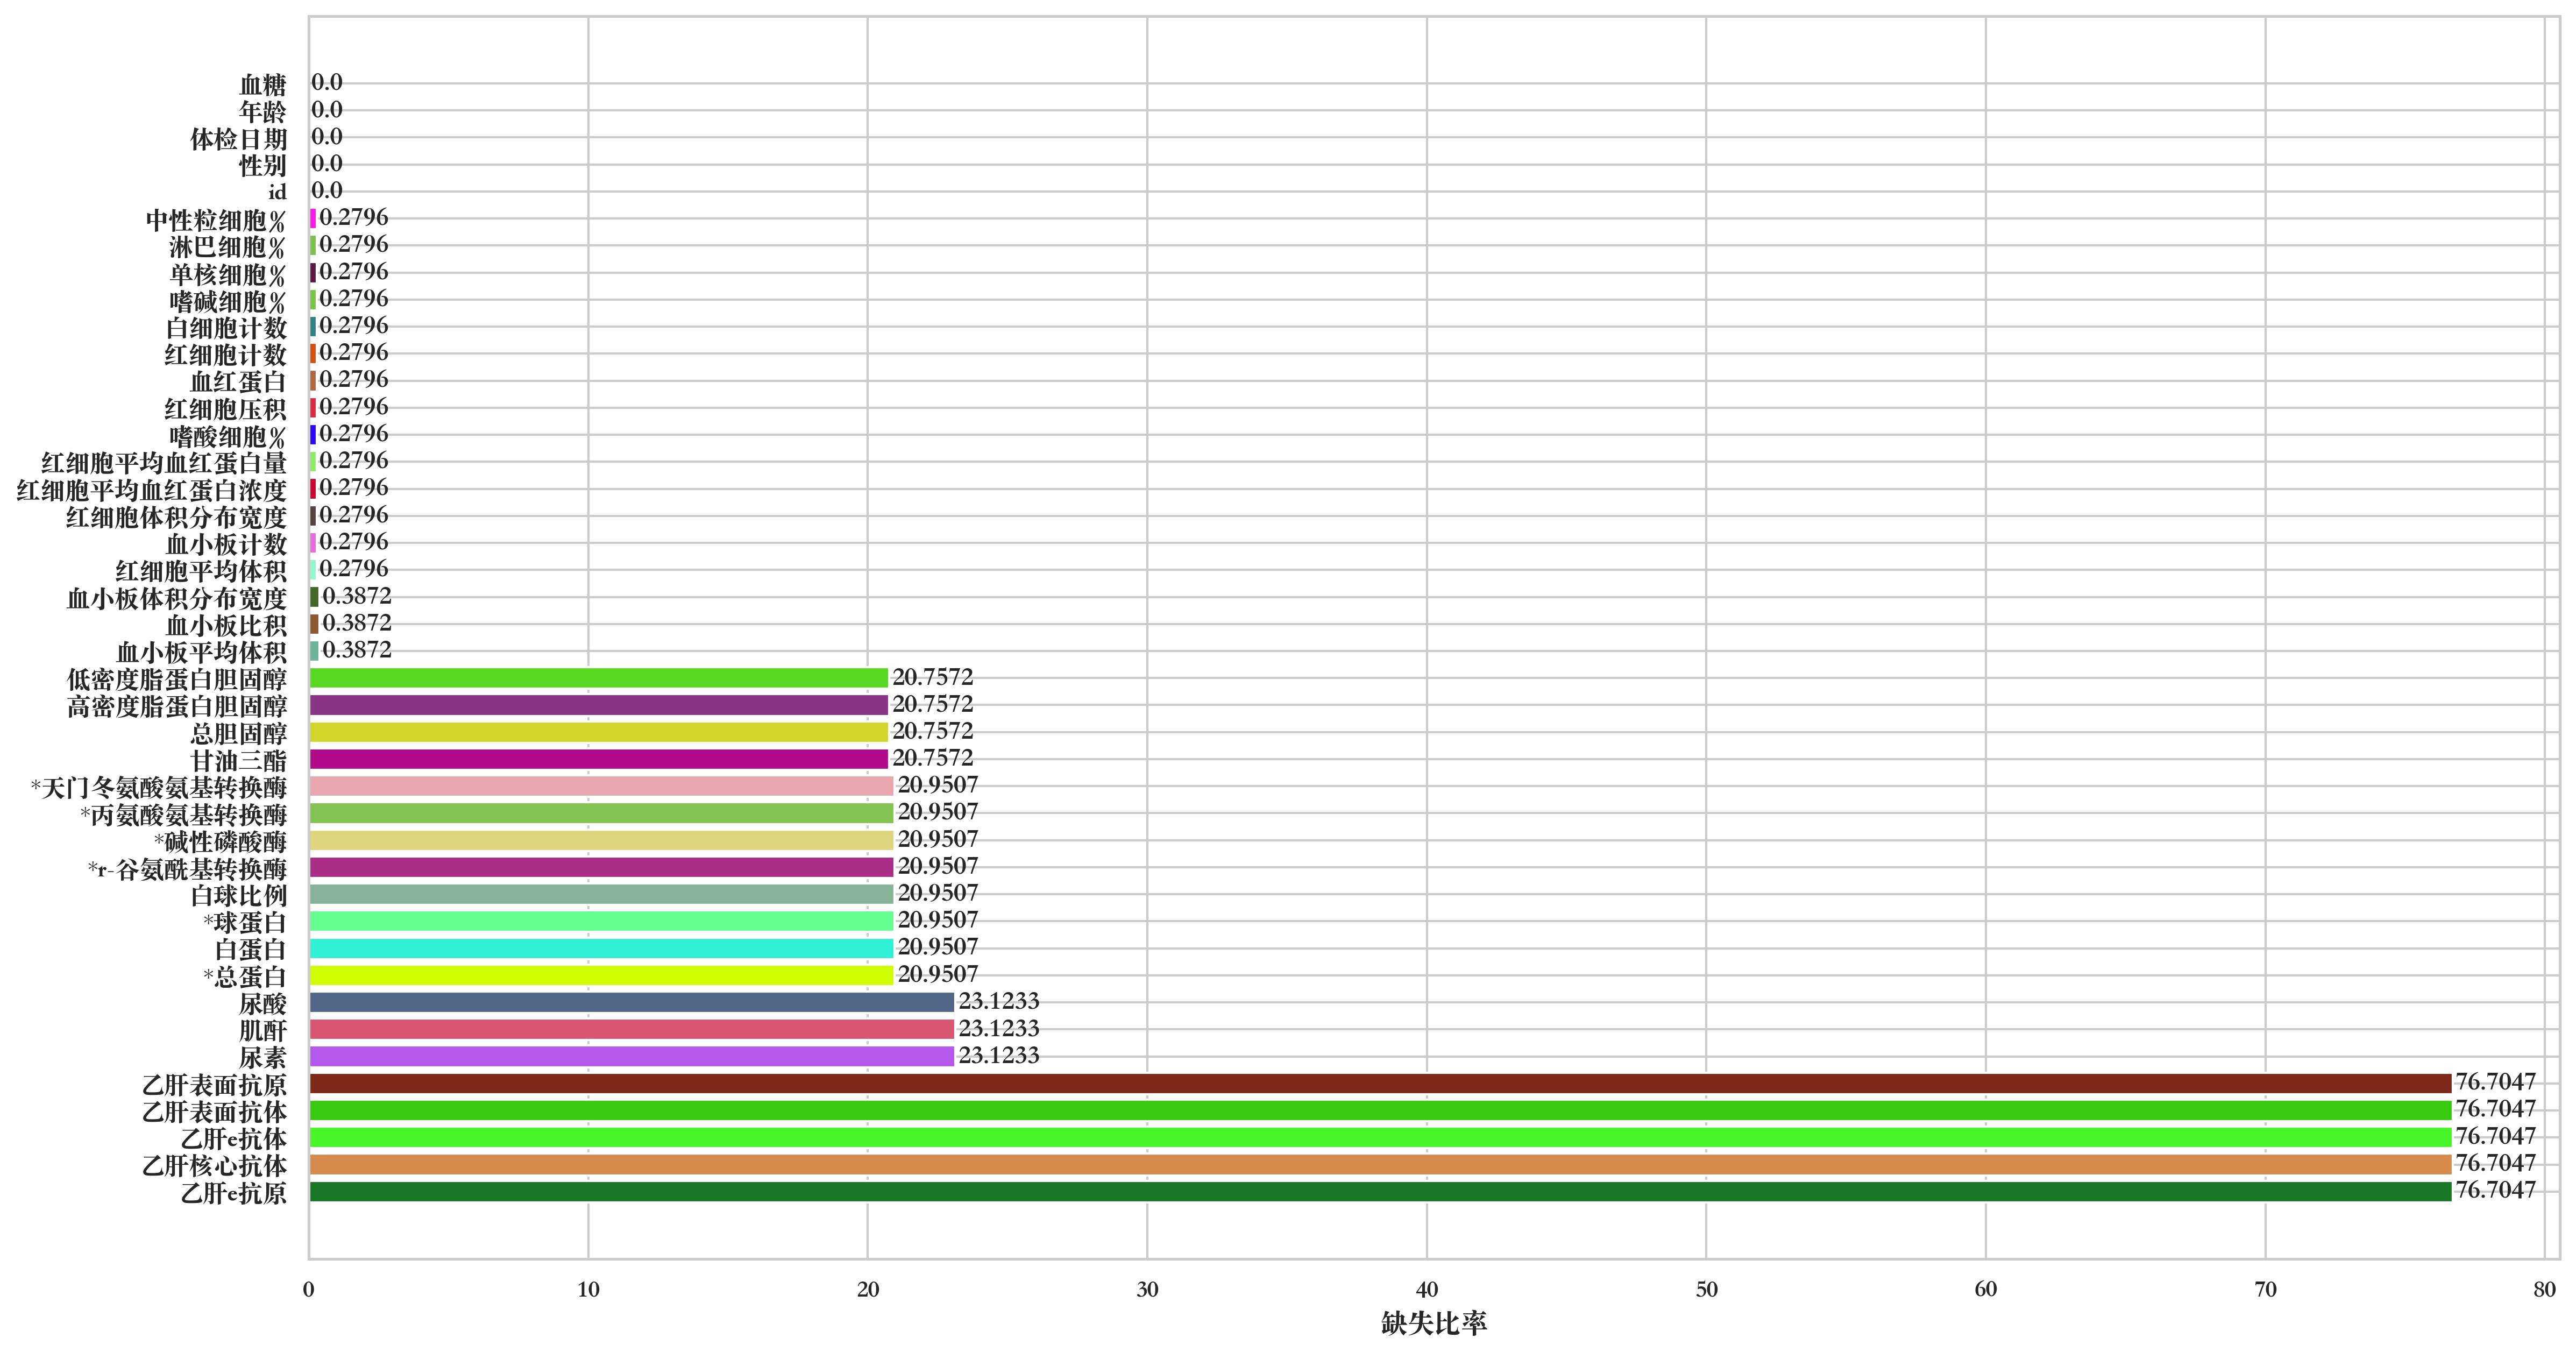

In [7]:
import random


plt.subplots(figsize=(18, 10), dpi=300)
plt.rcParams["font.sans-serif"] = ["Songti SC"] 

plt.barh(
    missing_rate_df["col_name"],
    missing_rate_df["Missing_Ratio(%)"],
    color=[
        f"#{random.randint(0, 255):02x}{random.randint(0, 255):02x}{random.randint(0, 255):02x}"
        for _ in range(len(data))
    ],
)

for i, v in enumerate(missing_rate_df["Missing_Ratio(%)"]):
    plt.text(v + 0.1, i, str(v), va="center")

plt.xlabel("缺失比率")

性别固定编码，保留未知类别与原始年龄

In [8]:
# 固定映射是逐行转换，不需要从验证数据学习。未知性别保留并单独标记。
sex_mapping = {"女": 0., "男": 1.}
for frame in (data, validation_data):
    frame["性别"] = frame["性别"].map(sex_mapping)
    frame["性别未知"] = frame["性别"].isna().astype(float)
print(sex_mapping)
print("训练集未知性别记录数:", int(data["性别未知"].sum()))

{'女': 0.0, '男': 1.0}
训练集未知性别记录数: 1


女=0、男=1，未知性别为 NaN 并增加未知标记，保留全部行。年龄保持原始连续数值；标准化后也保持浮点数。

- id 与体检日期不作为本轮预测特征；划分前的原始表仍保留二者，便于核对样本边界。

In [9]:
# id 用来核对样本和输出顺序；日期本轮不入模。目标显式命名，不依赖最后一列。
data = data.drop(columns=["id", "体检日期"])
validation_data = validation_data.drop(columns=["id", "体检日期"])

- 乙肝五项先保留。缺失多或线性相关性低都不足以证明删除有益，后续用训练集同折消融判断。

In [10]:
hepatitis_columns = ["乙肝表面抗原", "乙肝表面抗体", "乙肝e抗原", "乙肝e抗体", "乙肝核心抗体"]
# 保留原始列，此处不执行 drop。
assert set(hepatitis_columns).issubset(data.columns)

以下箱型图仅描述训练集的检验值分布，不把箱线图中的离群点直接判定为错误。年龄和性别的展示方式不影响模型保留这些输入。

# 预处理


保留全部记录、原始缺失值及极端检验值。没有可核验的录入错误判据时，不按缺失率或经验阈值删行。

填补后的副本仅用于训练集探索与 OLS；模型输入保留 NaN，由各训练折的填补器估计中位数并增加缺失指示。血糖目标不参与填补。

In [11]:
unfilled_train_data = data.copy()
feature_columns = data.columns.drop("血糖")
missing_ratio = unfilled_train_data[feature_columns].isna().mean(axis=1)
print("缺失率 >20% 的训练记录（保留）:", int((missing_ratio > 0.2).sum()))
exploration_imputer = SimpleImputer(strategy="median", keep_empty_features=True)
data.loc[:, feature_columns] = exploration_imputer.fit_transform(unfilled_train_data[feature_columns])
assert len(data) == len(train_raw_data)
assert len(validation_data) == len(validation_raw_data)
print("完整训练/开发验证形状:", data.shape, validation_data.shape)

缺失率 >20% 的训练记录（保留）: 1037
完整训练/开发验证形状: (4649, 41) (1993, 41)


再次查看数据矩阵的分布情况


In [12]:
data.describe()

,性别,年龄,*天门冬氨酸氨基转换酶,*丙氨酸氨基转换酶,*碱性磷酸酶,*r-谷氨酰基转换酶,*总蛋白,白蛋白,*球蛋白,白球比例,...,血小板平均体积,血小板体积分布宽度,血小板比积,中性粒细胞%,淋巴细胞%,单核细胞%,嗜酸细胞%,嗜碱细胞%,血糖,性别未知
count,4649.000000,4649.000000,4649.000000,4649.000000,4649.000000,4649.000000,4649.000000,4649.000000,4649.000000,4649.000000,...,4649.000000,4649.000000,4649.000000,4649.000000,4649.000000,4649.000000,4649.000000,4649.000000,4649.000000,4649.000000
mean,0.502904,45.718004,26.142846,26.189400,86.721716,36.056797,76.831648,45.883218,30.937954,1.501020,...,10.599634,13.362185,0.265624,56.775070,33.765907,6.833534,2.021510,0.604302,5.626855,0.000215
std,0.500045,13.022185,10.881714,19.063615,22.642191,36.621184,3.587654,2.310416,3.178541,0.198632,...,1.012228,2.223672,0.061201,7.836292,7.294438,1.556390,1.695886,0.292584,1.474255,0.014666
min,0.000000,3.000000,10.040000,0.120000,22.980000,6.360000,57.320000,29.540000,7.060000,0.520000,...,7.000000,8.000000,0.042000,21.100000,9.700000,3.100000,0.000000,0.000000,3.070000,0.000000
25%,0.000000,35.000000,21.220000,16.760000,74.040000,19.860000,74.920000,44.690000,29.220000,1.400000,...,10.000000,11.700000,0.226000,51.600000,28.800000,5.800000,0.900000,0.400000,4.940000,0.000000
50%,1.000000,45.000000,23.910000,21.400000,84.460000,26.300000,76.720000,45.850000,30.820000,1.490000,...,10.600000,13.000000,0.260000,56.800000,33.600000,6.700000,1.600000,0.600000,5.310000,0.000000
75%,1.000000,55.000000,27.570000,28.810000,95.470000,37.090000,78.770000,47.130000,32.500000,1.590000,...,11.200000,14.700000,0.300000,62.100000,38.600000,7.700000,2.500000,0.700000,5.770000,0.000000
max,1.000000,93.000000,281.210000,388.000000,345.730000,736.990000,100.410000,54.080000,66.180000,7.120000,...,15.200000,25.300000,0.710000,84.500000,73.600000,23.200000,19.100000,3.400000,38.430000,1.000000


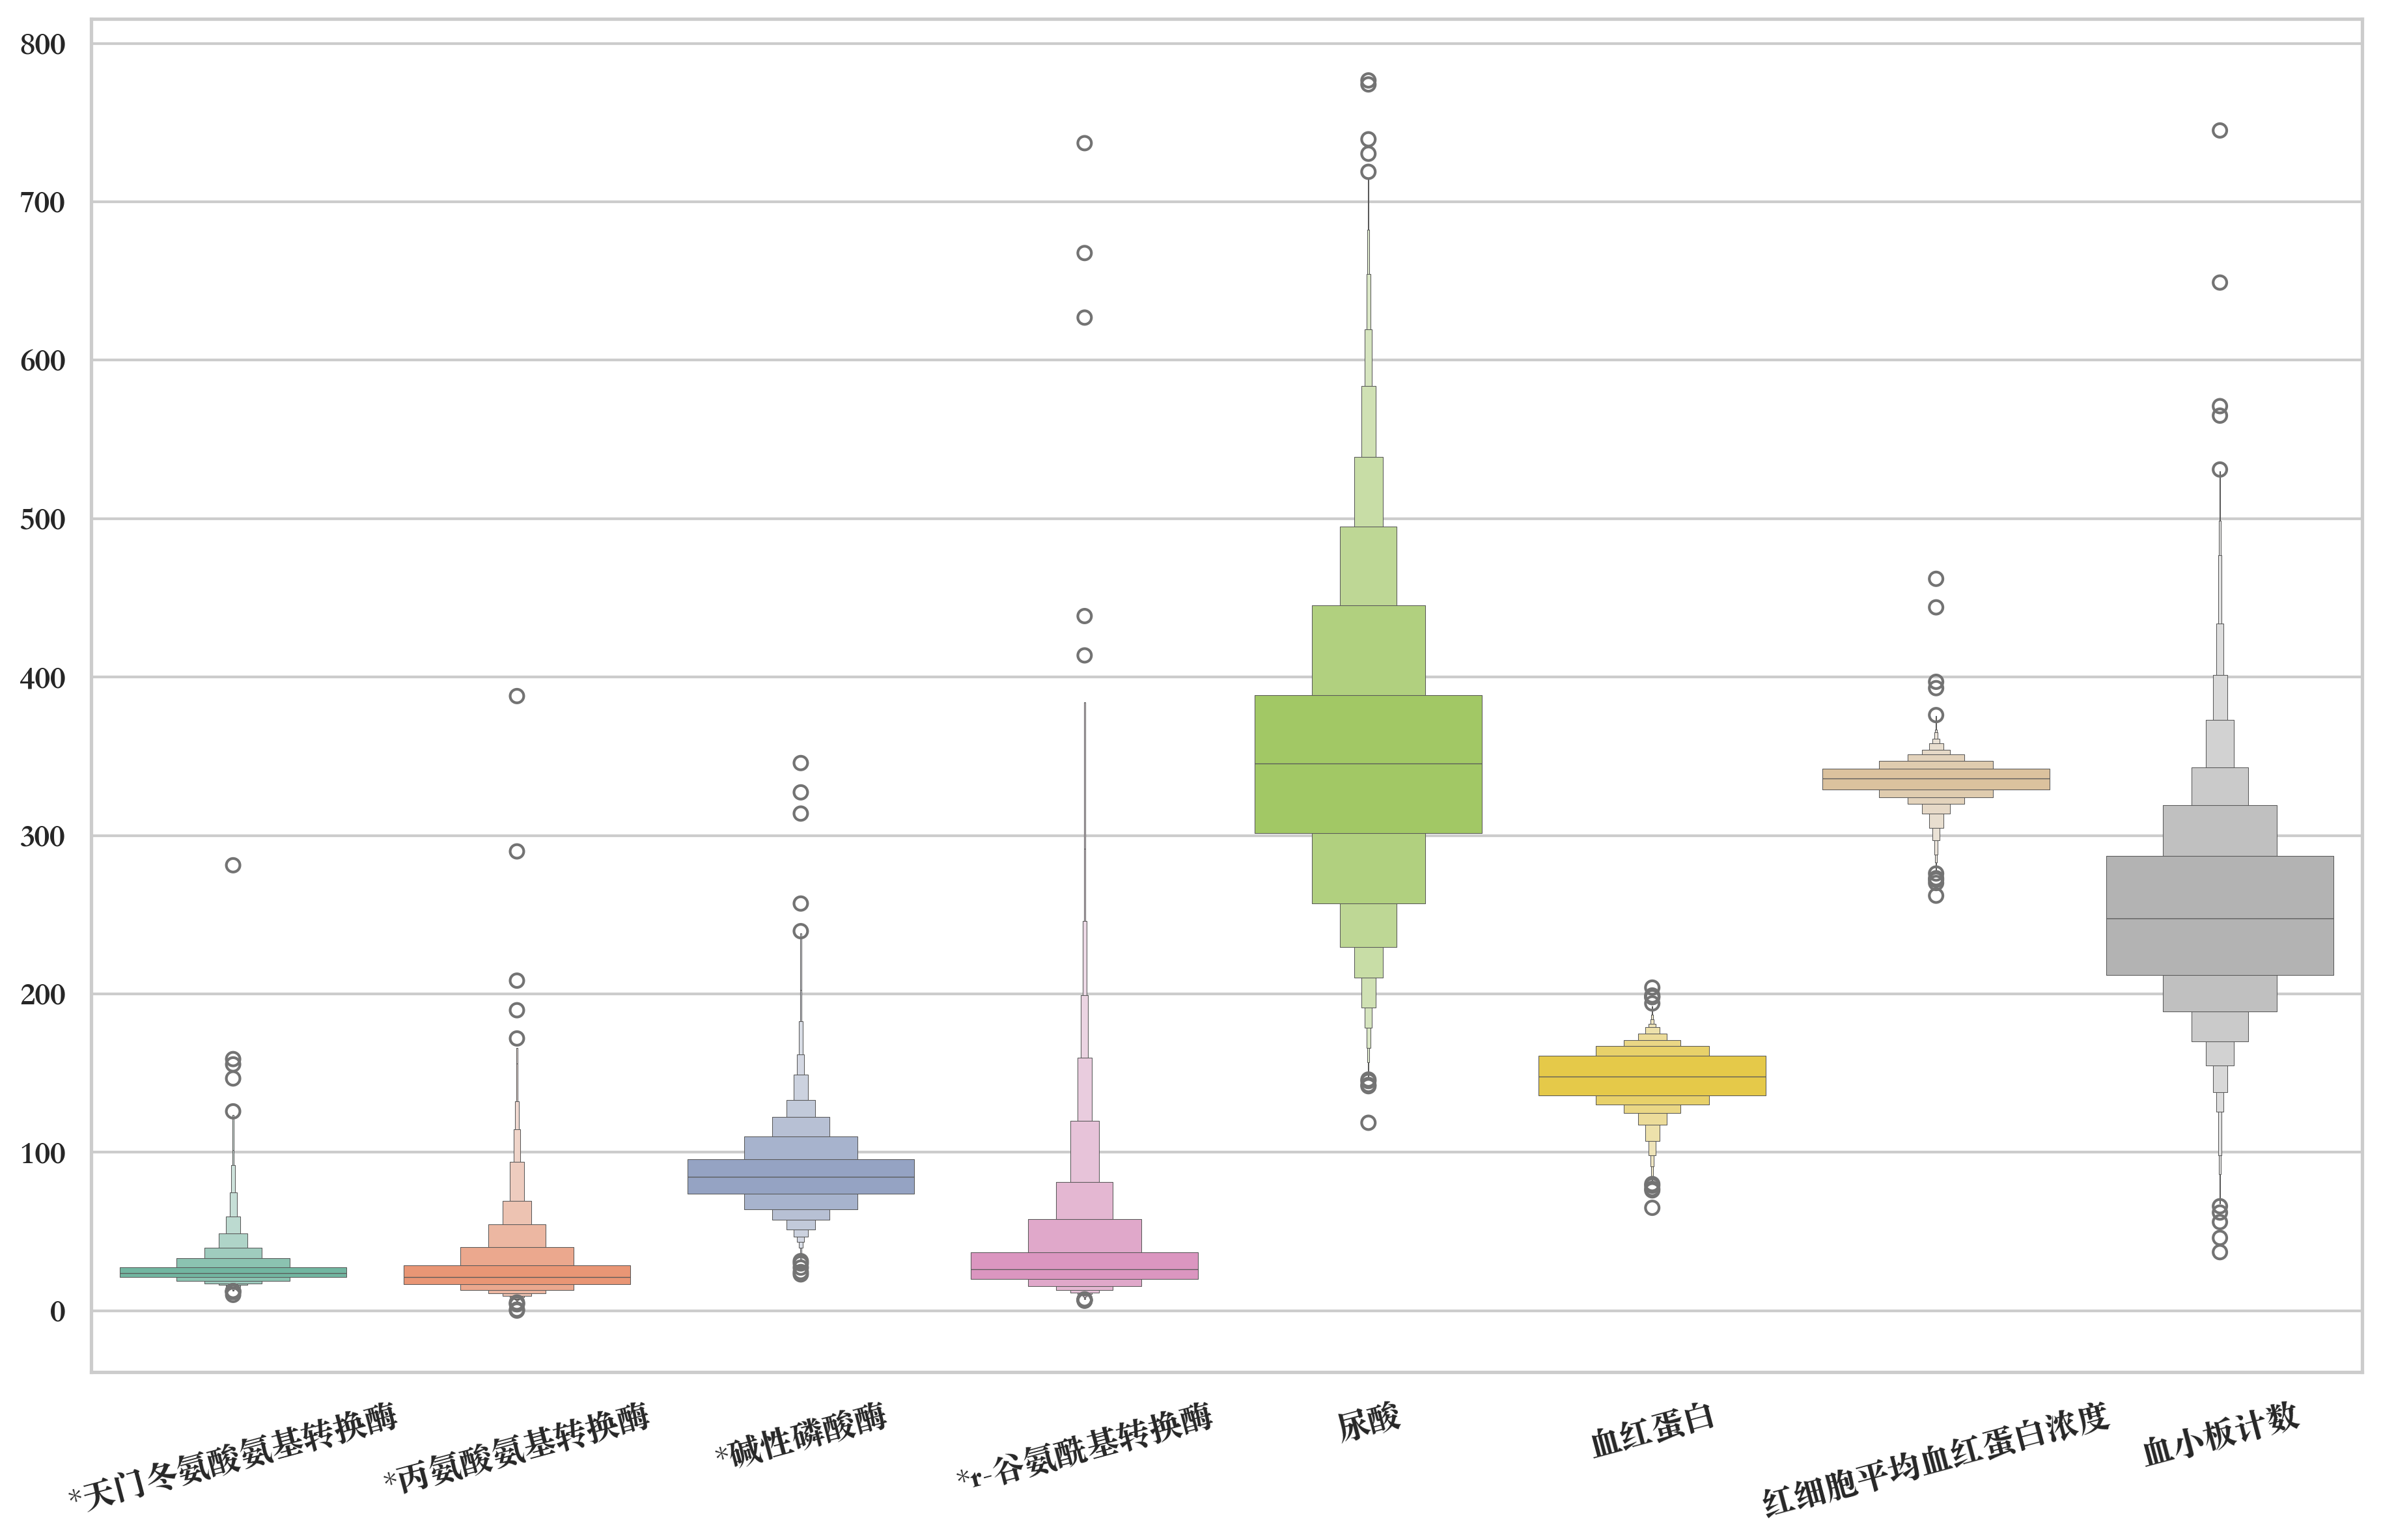

In [13]:
plt.subplots(figsize=(15, 9), dpi=300)

ax = sns.boxenplot(
    data=data.loc[
        :,
        [
            "*天门冬氨酸氨基转换酶",
            "*丙氨酸氨基转换酶",
            "*碱性磷酸酶",
            "*r-谷氨酰基转换酶",
            "尿酸",
            "血红蛋白",
            "红细胞平均血红蛋白浓度",
            "血小板计数",
        ],
    ],
    outlier_prop=0.05,
    palette="Set2",
    linewidth=0.25,
)
plt.setp(ax.get_xticklabels(), rotation=15)
plt.tick_params(labelsize=12)

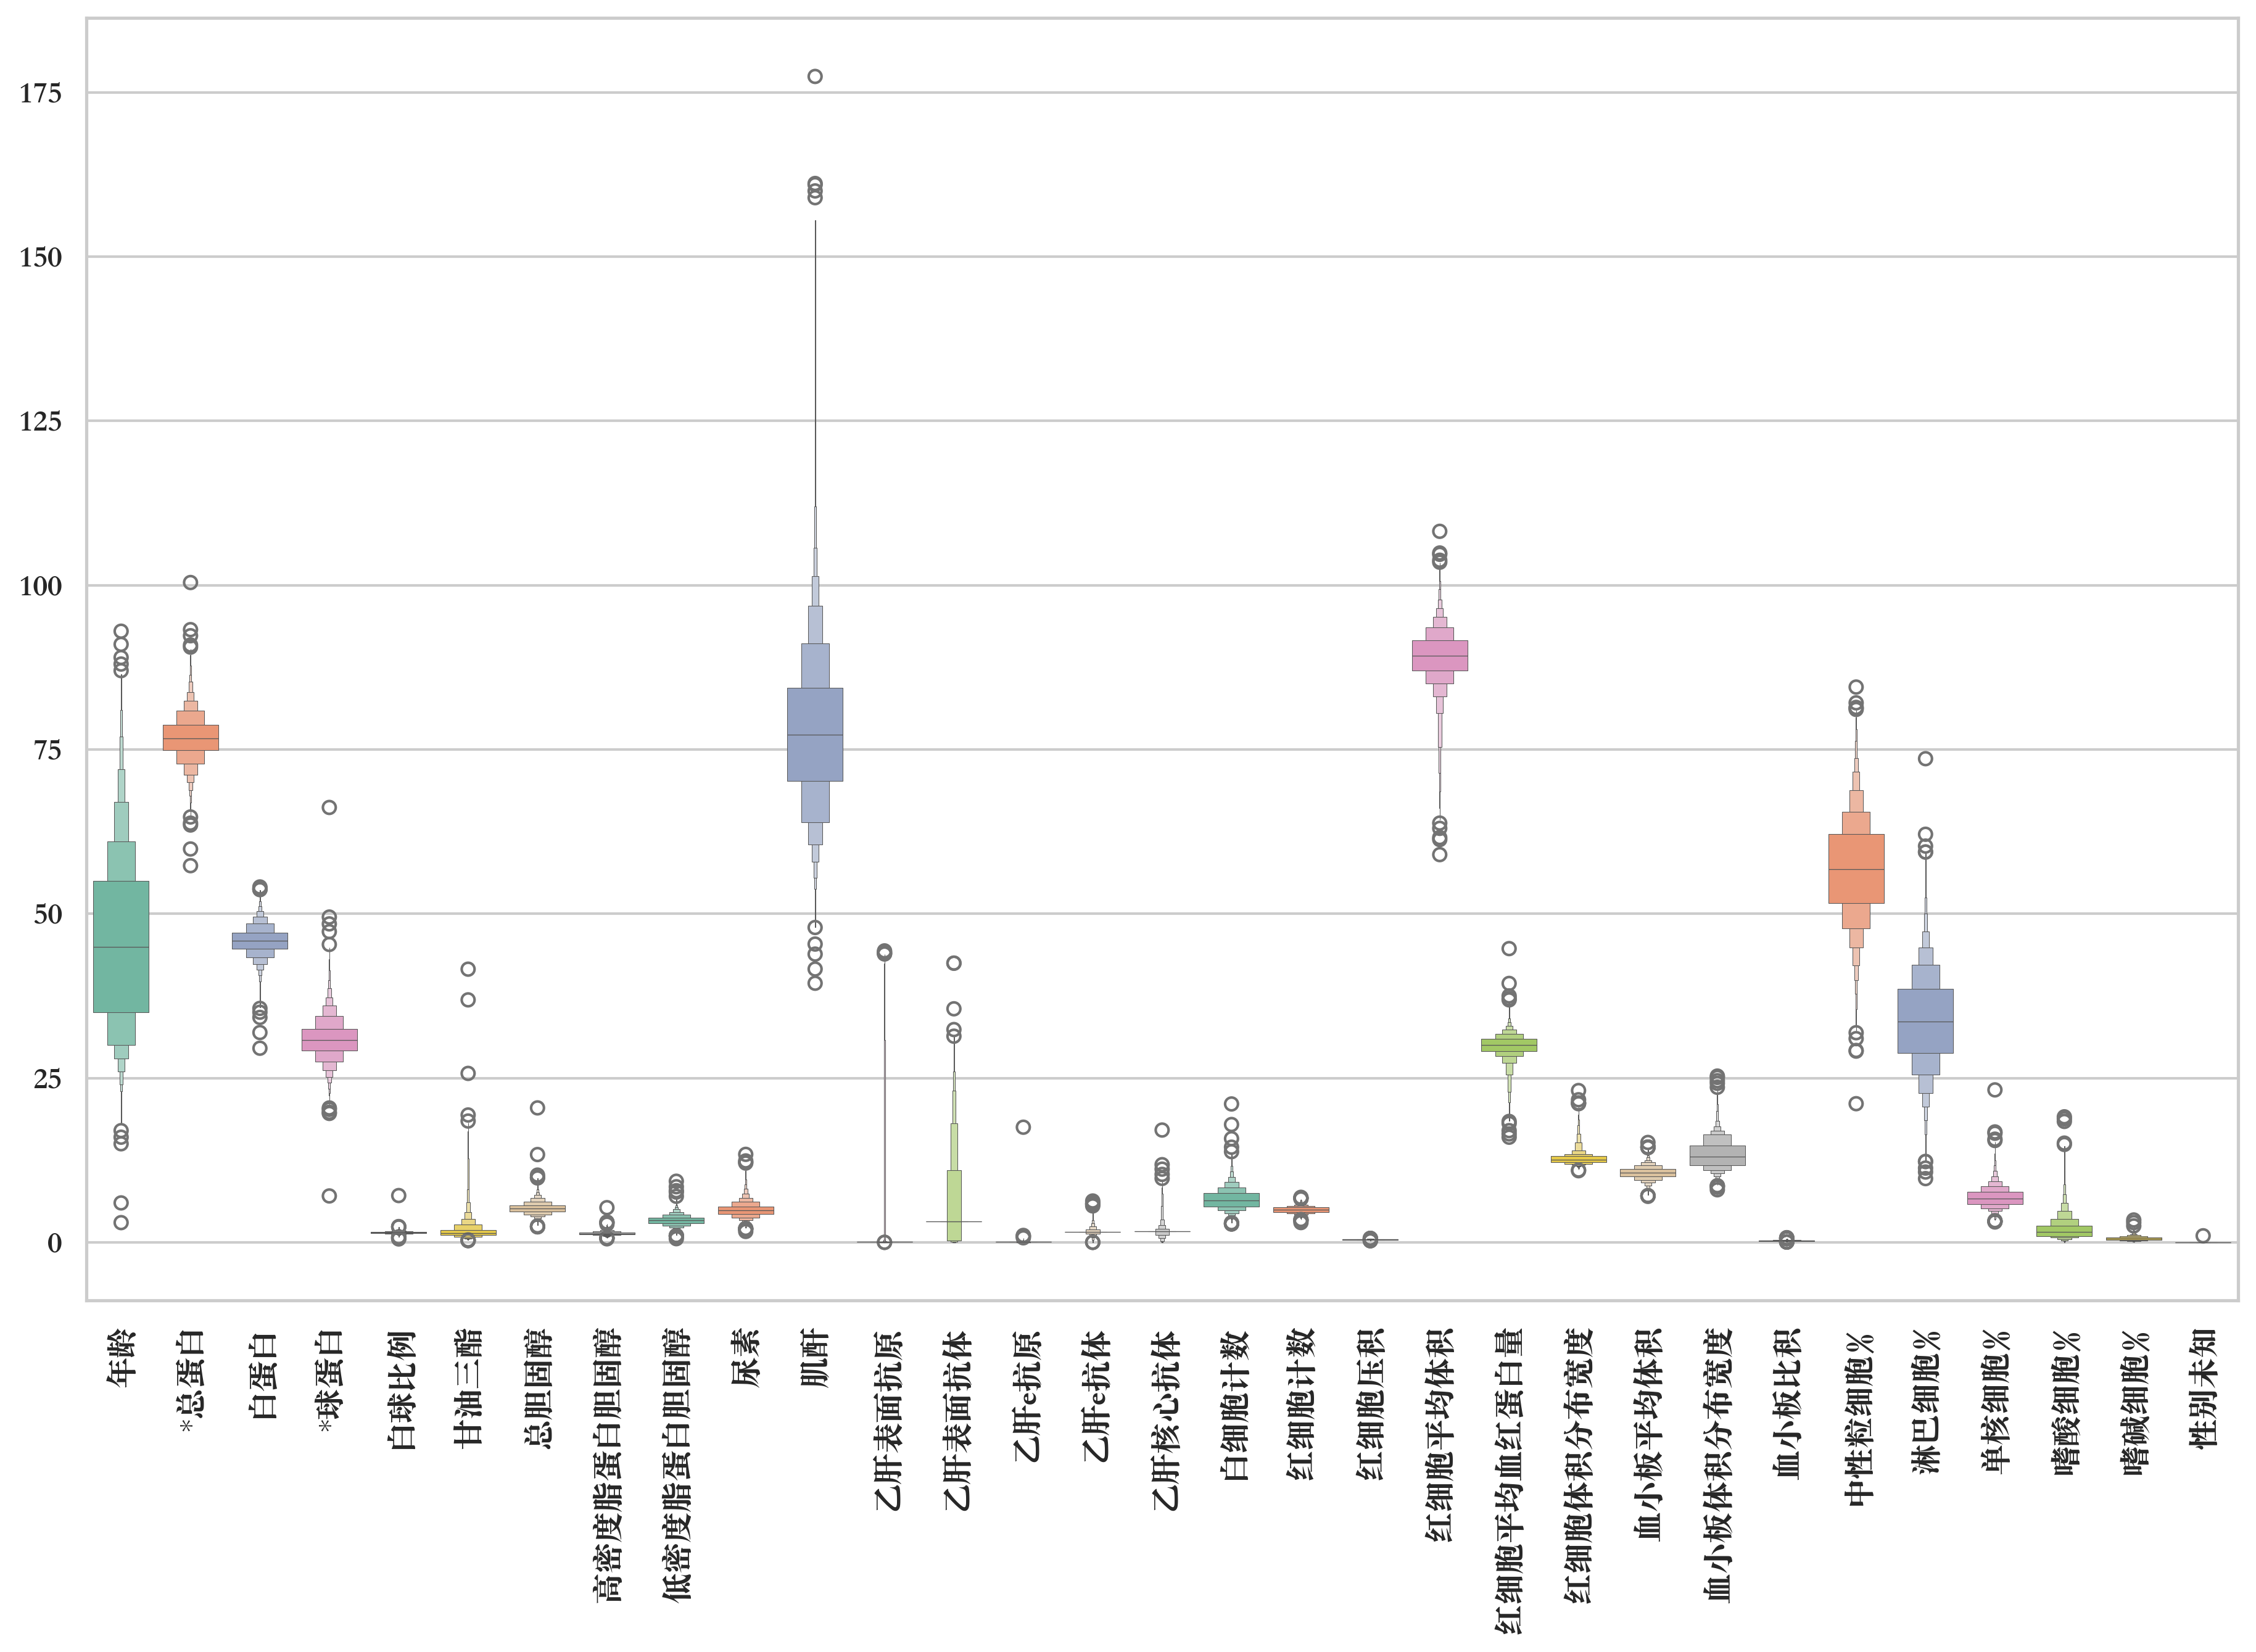

In [15]:
plt.subplots(figsize=(15, 9), dpi=300)
cols = [
    i
    for i in data.columns
    if i
    not in [
        "*天门冬氨酸氨基转换酶",
        "*丙氨酸氨基转换酶",
        "*碱性磷酸酶",
        "*r-谷氨酰基转换酶",
        "尿酸",
        "血红蛋白",
        "红细胞平均血红蛋白浓度",
        "血小板计数",
        "性别",
        "血糖",
    ]
]
ax = sns.boxenplot(data[cols], outlier_prop=0.03, palette="Set2", linewidth=0.25)
plt.setp(ax.get_xticklabels(), rotation=90)
plt.tick_params(labelsize=12)

In [16]:
# 原来的阈值只用于统计，不删样本、不裁剪目标，也不改变预测输入。
outlier_limits = {
    "*天门冬氨酸氨基转换酶": 200, "*丙氨酸氨基转换酶": 250,
    "*r-谷氨酰基转换酶": 600, "血小板计数": 600,
    "*球蛋白": 60, "甘油三酯": 30, "肌酐": 175,
}
extreme_counts = pd.Series({
    name: int((unfilled_train_data[name] > limit).sum())
    for name, limit in outlier_limits.items()
}, name="超过原阈值的记录数（均保留）")
print(extreme_counts)
assert unfilled_train_data.index.equals(train_raw_data.index)
assert validation_data.index.equals(validation_raw_data.index)

*天门冬氨酸氨基转换酶    1
*丙氨酸氨基转换酶      2
*r-谷氨酰基转换酶     3
血小板计数          2
*球蛋白           1
甘油三酯           2
肌酐             1
Name: 超过原阈值的记录数（均保留）, dtype: int64


In [ ]:
# 当前模型始终使用本轮内存数据，不生成或读取旧的填补/PCA 中间表。

多重线性回归分析（仅训练集探索；下方拟合指标不作为验证成绩）

In [17]:
import statsmodels.api as sm

# 仅为训练拟合诊断。目标显式取列，新增特征不会意外混入血糖。
x = sm.add_constant(data.drop(columns="血糖"))
y = data["血糖"]
model = sm.OLS(y, x).fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                     血糖   R-squared:                       0.168
Model:                            OLS   Adj. R-squared:                  0.161
Method:                 Least Squares   F-statistic:                     23.34
Date:                Wed, 11 Nov 2026   Prob (F-statistic):          3.43e-153
Time:                        20:33:12   Log-Likelihood:                -7971.8
No. Observations:                4649   AIC:                         1.603e+04
Df Residuals:                    4608   BIC:                         1.629e+04
Df Model:                          40                                         
Covariance Type:            nonrobust                                         
===============================================================================
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const         -11.1004     48.819     -0.227      0.820    -106.810      84.609
性别              0.1546      0.073      2.124      0.034       0.012       0.297
年龄              0.0265      0.002     14.148      0.000       0.023       0.030
*天门冬氨酸氨基转换酶    -0.0068      0.003     -1.985      0.047      -0.014   -8.39e-05
*丙氨酸氨基转换酶       0.0106      0.002      5.144      0.000       0.007       0.015
*碱性磷酸酶          0.0021      0.001      2.232      0.026       0.000       0.004
*r-谷氨酰基转换酶      0.0016      0.001      2.378      0.017       0.000       0.003
*总蛋白            2.6374      1.047      2.519      0.012       0.585       4.690
白蛋白            -2.6478      1.048     -2.527      0.012      -4.702      -0.593
*球蛋白           -2.6025      1.045     -2.490      0.013      -4.651      -0.554
白球比例            0.3730      0.305      1.222      0.222      -0.225       0.971
甘油三酯            0.1218      0.021      5.925      0.000       0.081       0.162
总胆固醇           -0.0552      0.146     -0.379      0.705      -0.341       0.230
高密度脂蛋白胆固醇       0.0069      0.176      0.039      0.969      -0.339       0.353
低密度脂蛋白胆固醇       0.1605      0.153      1.048      0.295      -0.140       0.461
尿素              0.0856      0.020      4.383      0.000       0.047       0.124
肌酐           2.644e-05      0.002      0.011      0.991      -0.005       0.005
尿酸             -0.0026      0.000     -8.169      0.000      -0.003      -0.002
乙肝表面抗原          0.0048      0.007      0.642      0.521      -0.010       0.019
乙肝表面抗体          0.0041      0.005      0.860      0.390      -0.005       0.013
乙肝e抗原          -0.0154      0.080     -0.193      0.847      -0.171       0.141
乙肝e抗体           0.0105      0.059      0.178      0.859      -0.106       0.127
乙肝核心抗体          0.0602      0.032      1.898      0.058      -0.002       0.122
白细胞计数           0.0598      0.015      3.984      0.000       0.030       0.089
红细胞计数           2.1422      0.696      3.078      0.002       0.778       3.507
血红蛋白            0.0651      0.038      1.695      0.090      -0.010       0.140
红细胞压积         -44.8730     17.154     -2.616      0.009     -78.503     -11.243
红细胞平均体积         0.0920      0.097      0.947      0.344      -0.099       0.283
红细胞平均血红蛋白量     -0.0425      0.252     -0.168      0.866      -0.537       0.452
红细胞平均血红蛋白浓度    -0.0126      0.021     -0.601      0.548      -0.054       0.029
红细胞体积分布宽度      -0.0873      0.030     -2.916      0.004      -0.146      -0.029
血小板计数          -0.0013      0.003     -0.535      0.593      -0.006       0.004
血小板平均体积         0.0195      0.061      0.323      0.747      -0.099       0.138
血小板体积分布宽度       0.0132      0.012      1.119      0.263      -0.010       0.036
血小板比积           0.4166      2.386      0.175      0.861      -4.262       5.095
中性粒细胞%          0.1142      0.482      0.23

MSE: 1.807
R²: 0.168


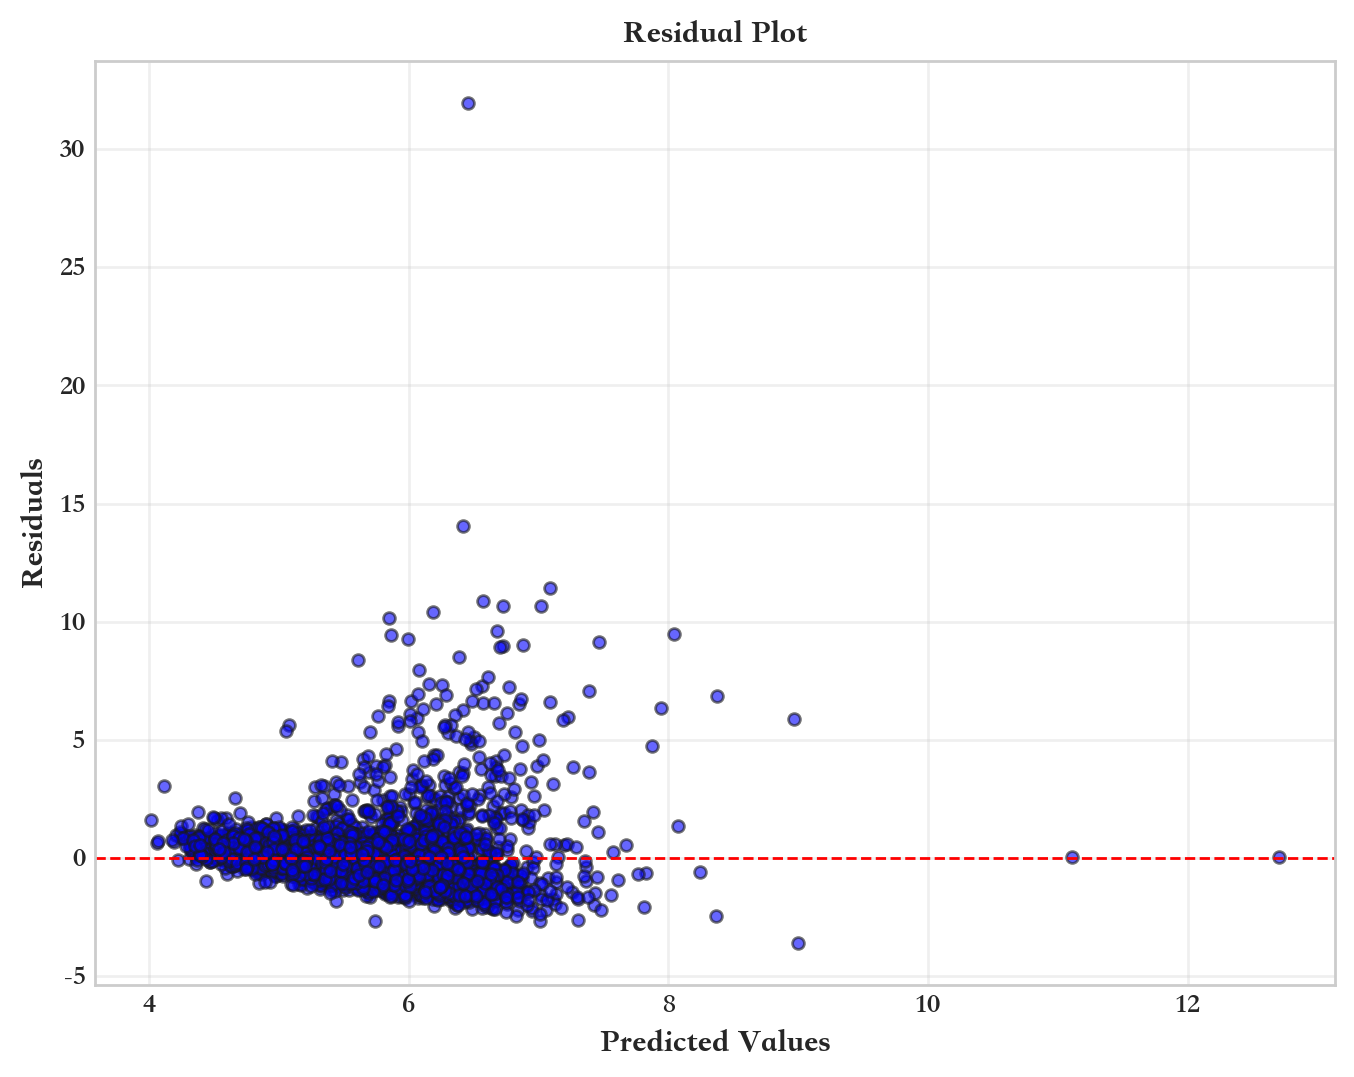

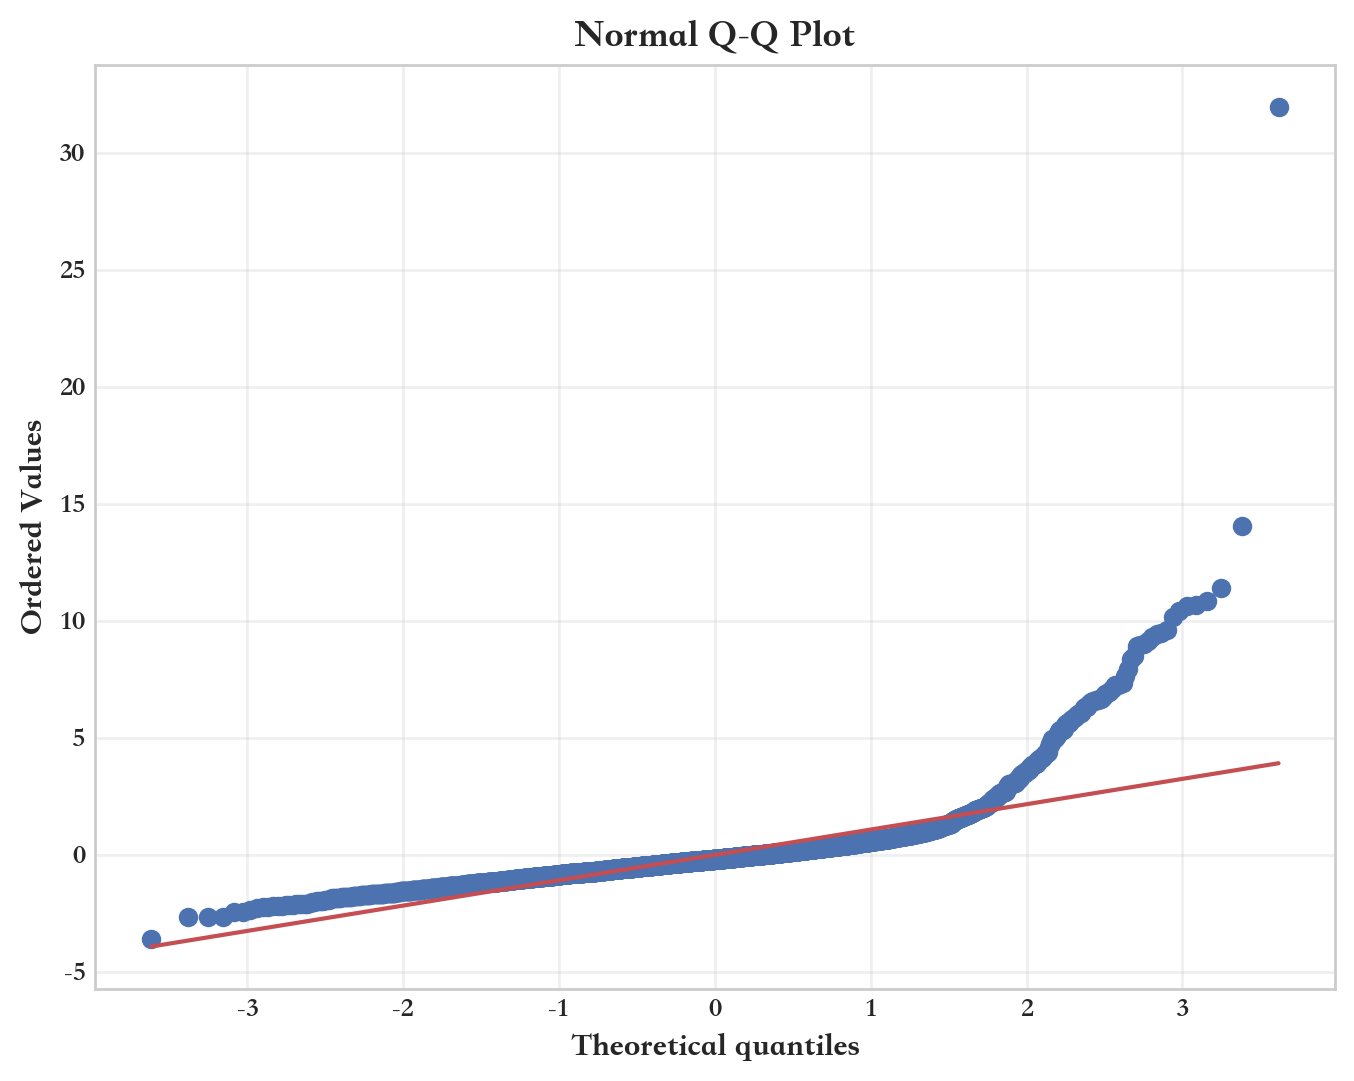

In [18]:
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as stats
from sklearn.metrics import mean_squared_error, r2_score

# 计算预测值
y_pred = model.predict(x)

# 计算MSE和R²
mse = mean_squared_error(y, y_pred)
r2 = r2_score(y, y_pred)

# 打印结果
print(f"MSE: {mse:.3f}")
print(f"R²: {r2:.3f}")

# 计算残差
residuals = y - y_pred

# print(plt.style.available)

# 设置全局风格
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"font.size": 10, "figure.dpi": 200, "font.sans-serif": "Songti SC"})

# 绘制残差图
plt.figure(figsize=(8, 6))
plt.scatter(y_pred, residuals, alpha=0.6, color="blue", edgecolor="k", s=18)
plt.axhline(y=0, color="red", linestyle="--", linewidth=1.0)
plt.title("Residual Plot", fontsize=12, fontweight="bold")
plt.xlabel("Predicted Values", fontsize=12)
plt.ylabel("Residuals", fontsize=12)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.grid(alpha=0.3)
plt.show()

# 绘制QQ图
plt.figure(figsize=(8, 6))
stats.probplot(residuals, dist="norm", plot=plt)
plt.title("Normal Q-Q Plot", fontsize=14, fontweight="bold")
plt.grid(alpha=0.3)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.show()

训练集标准化探索（与真正的模型预处理独立）

In [19]:
X_train_raw = unfilled_train_data.drop(columns="血糖").copy()
X_validation_raw = validation_data.drop(columns="血糖").copy()
train_labels = unfilled_train_data["血糖"].to_numpy()
validation_labels = validation_data["血糖"].to_numpy()
assert X_train_raw.index.intersection(X_validation_raw.index).empty
assert len(X_train_raw) == len(train_raw_data) == 4649
assert len(X_validation_raw) == len(validation_raw_data) == 1993
assert "血糖" not in X_train_raw.columns

# 仅在训练数据上拟合的探索副本，不传给后续模型搜索。
dataset = data.drop(columns="血糖")
target = data["血糖"]
exploration_scaler = StandardScaler()
z_score = pd.DataFrame(exploration_scaler.fit_transform(dataset),
                       columns=dataset.columns, index=dataset.index)
assert z_score["年龄"].nunique() == X_train_raw["年龄"].nunique()
z_score.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4649 entries, 5640 to 595
Data columns (total 40 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   性别           4649 non-null   float64
 1   年龄           4649 non-null   float64
 2   *天门冬氨酸氨基转换酶  4649 non-null   float64
 3   *丙氨酸氨基转换酶    4649 non-null   float64
 4   *碱性磷酸酶       4649 non-null   float64
 5   *r-谷氨酰基转换酶   4649 non-null   float64
 6   *总蛋白         4649 non-null   float64
 7   白蛋白          4649 non-null   float64
 8   *球蛋白         4649 non-null   float64
 9   白球比例         4649 non-null   float64
 10  甘油三酯         4649 non-null   float64
 11  总胆固醇         4649 non-null   float64
 12  高密度脂蛋白胆固醇    4649 non-null   float64
 13  低密度脂蛋白胆固醇    4649 non-null   float64
 14  尿素           4649 non-null   float64
 15  肌酐           4649 non-null   float64
 16  尿酸           4649 non-null   float64
 17  乙肝表面抗原       4649 non-null   float64
 18  乙肝表面抗体       4649 non-null   float64
 19  乙肝e抗原    

In [20]:
from sklearn.linear_model import Lasso

model = Lasso(alpha=0.05)

# 训练模型
model.fit(z_score, target)

# 输出特征重要性
importances = pd.DataFrame({"feature": z_score.columns, "importance": abs(model.coef_)})
importances = importances.sort_values("importance", ascending=False).reset_index(
    drop=True
)
importances

,feature,importance
0,年龄,0.296907
1,甘油三酯,0.173759
2,红细胞平均血红蛋白浓度,0.105182
3,*丙氨酸氨基转换酶,0.098668
4,红细胞计数,0.089076
5,尿酸,0.069228
6,尿素,0.052771
7,白细胞计数,0.051257
8,低密度脂蛋白胆固醇,0.037084
9,红细胞平均体积,0.035622


热力图相关性分析


(array([ 0.5,  1.5,  2.5,  3.5,  4.5,  5.5,  6.5,  7.5,  8.5,  9.5, 10.5,
        11.5, 12.5, 13.5, 14.5, 15.5, 16.5, 17.5, 18.5, 19.5, 20.5, 21.5,
        22.5, 23.5, 24.5, 25.5, 26.5, 27.5, 28.5, 29.5, 30.5, 31.5, 32.5,
        33.5, 34.5, 35.5, 36.5, 37.5, 38.5, 39.5]),
 [Text(0, 0.5, '性别'),
  Text(0, 1.5, '年龄'),
  Text(0, 2.5, '*天门冬氨酸氨基转换酶'),
  Text(0, 3.5, '*丙氨酸氨基转换酶'),
  Text(0, 4.5, '*碱性磷酸酶'),
  Text(0, 5.5, '*r-谷氨酰基转换酶'),
  Text(0, 6.5, '*总蛋白'),
  Text(0, 7.5, '白蛋白'),
  Text(0, 8.5, '*球蛋白'),
  Text(0, 9.5, '白球比例'),
  Text(0, 10.5, '甘油三酯'),
  Text(0, 11.5, '总胆固醇'),
  Text(0, 12.5, '高密度脂蛋白胆固醇'),
  Text(0, 13.5, '低密度脂蛋白胆固醇'),
  Text(0, 14.5, '尿素'),
  Text(0, 15.5, '肌酐'),
  Text(0, 16.5, '尿酸'),
  Text(0, 17.5, '乙肝表面抗原'),
  Text(0, 18.5, '乙肝表面抗体'),
  Text(0, 19.5, '乙肝e抗原'),
  Text(0, 20.5, '乙肝e抗体'),
  Text(0, 21.5, '乙肝核心抗体'),
  Text(0, 22.5, '白细胞计数'),
  Text(0, 23.5, '红细胞计数'),
  Text(0, 24.5, '血红蛋白'),
  Text(0, 25.5, '红细胞压积'),
  Text(0, 26.5, '红细胞平均体积'),
  Text(0, 27.5, '红细胞平均血红蛋白量'

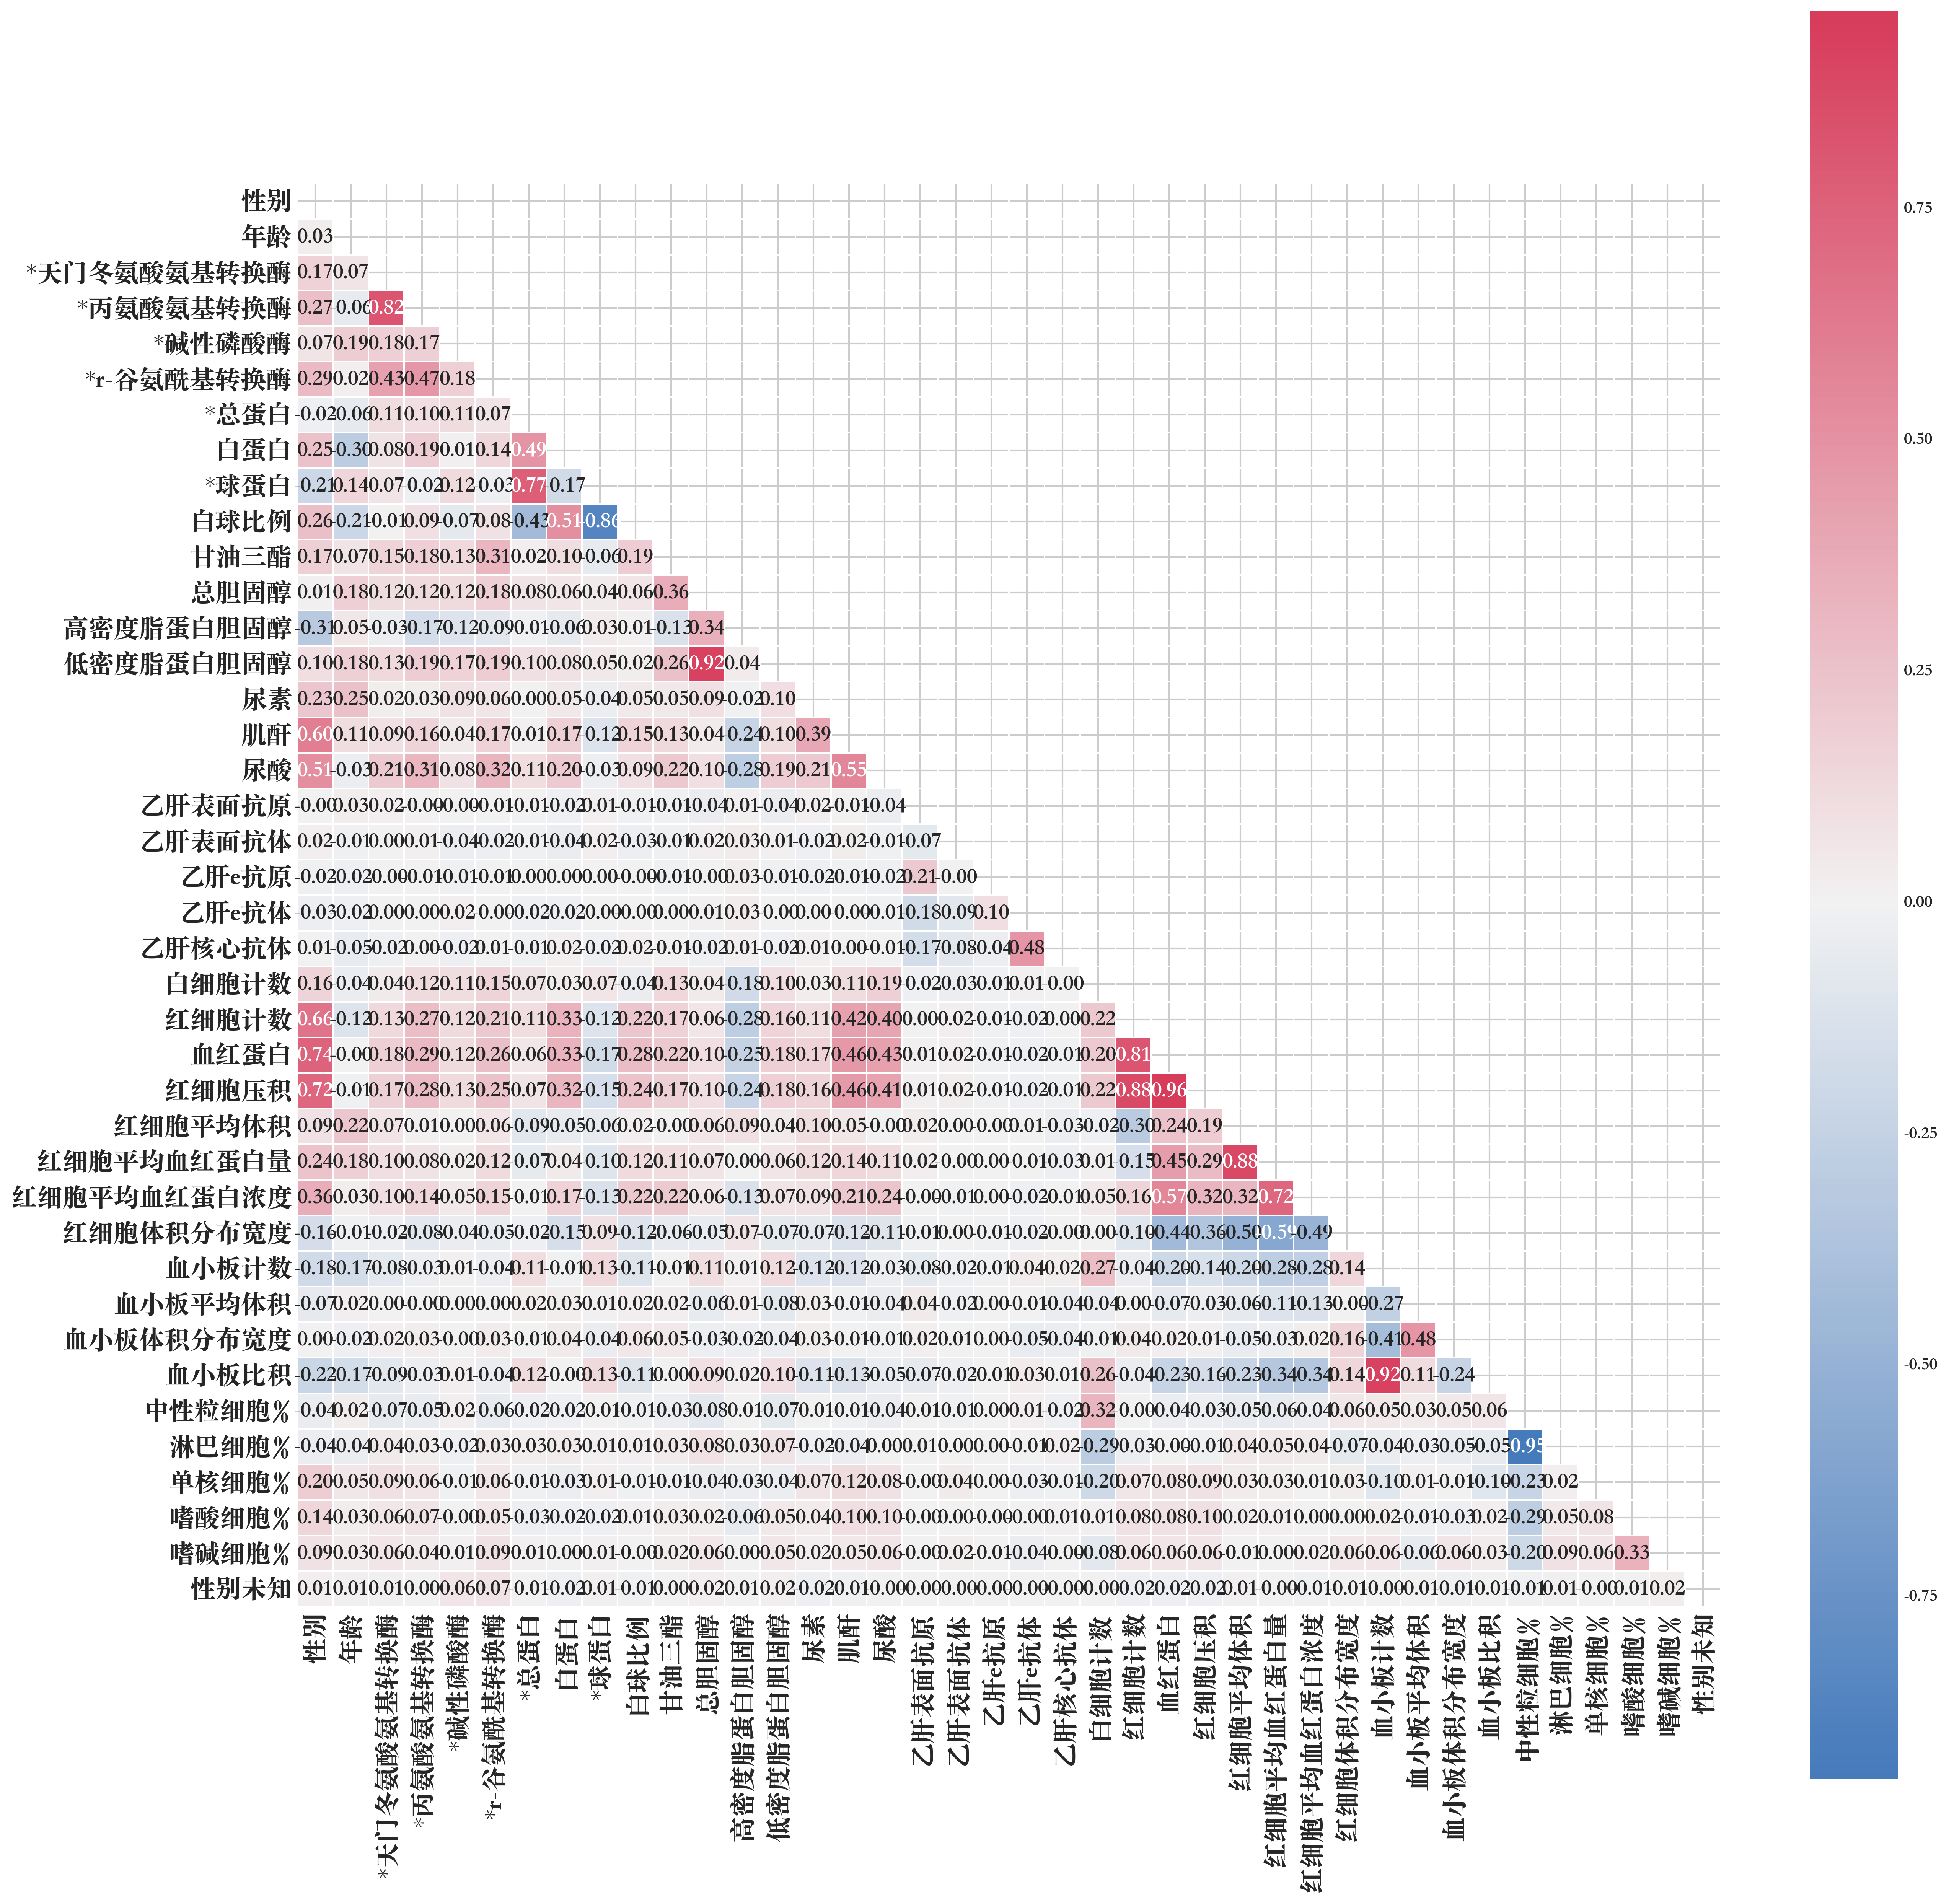

In [21]:
# 生成上三角掩码
mask = np.triu(np.ones_like(z_score.corr(), dtype=bool))

# 创建图形和子图
fig_corr, ax_corr = plt.subplots(figsize=(20, 20), dpi=300)

# 定义颜色映射
cmap = sns.diverging_palette(250, 5, as_cmap=True)

# seaborn.diverging_palette(h_neg, h_pos, s=75, l=50, sep=1, n=6, center='light', as_cmap=False)
# Make a diverging palette between two HUSL colors.
# Parameters:
# h_neg, h_pos : float in [0, 359]
# Anchor hues for negative and positive extents of the map
# as_cmap : bool, optional
# If True, return a matplotlib.colors.ListedColormap

sns.heatmap(
    data=z_score.corr(),
    mask=mask,
    cmap=cmap,
    center=0,
    fmt=".2f",
    square=True,
    annot=True,
    linewidth=0.5,
    ax=ax_corr,
    annot_kws={"fontsize": 14},
)

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

In [22]:
# 四种特征集 × 有/无 PCA，作为预先声明的训练集消融候选。
correlated_columns_to_drop = [
    "*天门冬氨酸氨基转换酶", "总胆固醇", "红细胞压积", "血红蛋白",
    "血小板比积", "红细胞平均血红蛋白量", "白球比例", "中性粒细胞%",
]
feature_sets = {
    "all": X_train_raw.columns.tolist(),
    "no_hepatitis": [c for c in X_train_raw.columns if c not in hepatitis_columns],
    "no_correlated": [c for c in X_train_raw.columns if c not in correlated_columns_to_drop],
    "legacy_drop": [c for c in X_train_raw.columns if c not in hepatitis_columns + correlated_columns_to_drop],
}

def make_preprocessor(representation="raw", feature_set="all", family="linear"):
    if representation not in ("raw", "pca") or family not in ("linear", "tree"):
        raise ValueError("未知的预处理配置")
    return Pipeline([
        ("columns", ColumnTransformer([("keep", "passthrough", feature_sets[feature_set])], remainder="drop")),
        ("imputer", SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True)),
        ("scaler", StandardScaler() if family == "linear" or representation == "pca" else "passthrough"),
        ("pca", PCA(n_components=0.98, svd_solver="full") if representation == "pca" else "passthrough"),
    ])

def make_model_pipeline(estimator, representation="raw", feature_set="all", family="linear"):
    return Pipeline([
        ("preprocess", make_preprocessor(representation, feature_set, family)),
        ("model", clone(estimator)),
    ])

def select_representation(estimator, name, family):
    """只用训练折比较。保守采用删列/PCA：五折均不劣于全特征原始表示。"""
    configs = [(r, f) for r in ("raw", "pca") for f in feature_sets]
    rows = []
    fold_losses = {}
    for representation, feature_set in configs:
        pipeline = make_model_pipeline(estimator, representation, feature_set, family)
        losses = -cross_val_score(pipeline, X_train_raw, train_labels, cv=cv,
                                 scoring="neg_mean_squared_error", n_jobs=SEARCH_N_JOBS)
        fold_losses[(representation, feature_set)] = losses
        rows.append({"representation": representation, "feature_set": feature_set,
                     "CV_MSE": float(losses.mean())})
    baseline = fold_losses[("raw", "all")]
    eligible = [("raw", "all")]
    for row in rows:
        key = (row["representation"], row["feature_set"])
        delta = fold_losses[key] - baseline
        row["delta_MSE_vs_raw_all"] = float(delta.mean())
        row["fold_wins_vs_raw_all"] = int((delta < 0).sum())
        row["eligible"] = key == ("raw", "all") or (bool((delta <= 0).all()) and delta.mean() < 0)
        if key != ("raw", "all") and row["eligible"]:
            eligible.append(key)
    chosen = min(eligible, key=lambda key: fold_losses[key].mean())
    report = pd.DataFrame(rows)
    report["selected"] = (report["representation"] == chosen[0]) & (report["feature_set"] == chosen[1])
    representation_reports[name] = report
    print(name, "选中预处理:", chosen)
    print(report.to_string(index=False))
    return make_model_pipeline(estimator, chosen[0], chosen[1], family)


def record_development(name, fitted_pipeline):
    prediction = fitted_pipeline.predict(X_validation_raw)
    result = {"model": name, "development_MSE": float(mean_squared_error(validation_labels, prediction)),
              "development_RMSE": float(np.sqrt(mean_squared_error(validation_labels, prediction))),
              "development_MAE": float(mean_absolute_error(validation_labels, prediction)),
              "development_R2": float(r2_score(validation_labels, prediction))}
    development_results.append(result)
    model_registry[name] = {"kind": "sklearn", "pipeline": fitted_pipeline}
    print(result)
    return prediction

print("默认保留全部特征；PCA 与删列通过训练折消融决定。")

默认保留全部特征；PCA 与删列通过训练折消融决定。


In [23]:
from factor_analyzer.factor_analyzer import calculate_kmo, calculate_bartlett_sphericity

# 仅作因子分析探索。奇异相关矩阵可能产生警告/非有限统计量；不据此决定预测特征。
factor_data = z_score.loc[:, z_score.std() > 0]
chi_square_value, p_value = calculate_bartlett_sphericity(factor_data)
kmo_per_item, kmo_overall = calculate_kmo(factor_data)
print("探索性 Bartlett 卡方值 / P值:", chi_square_value, p_value)
print("探索性 KMO:", kmo_overall)
print("以上指标不用于决定是否做 PCA；预测方案按训练折 MSE 比较。")

探索性 Bartlett 卡方值 / P值: 265836.81293890014 0.0
探索性 KMO: 0.46900030810931664
以上指标不用于决定是否做 PCA；预测方案按训练折 MSE 比较。


/Users/chengchong/anaconda3/lib/python3.10/site-packages/factor_analyzer/utils.py:244: UserWarning: The inverse of the variance-covariance matrix was calculated using the Moore-Penrose generalized matrix inversion, due to its determinant being at or very close to zero.
  warnings.warn(


达到98%方差的成分数: 29


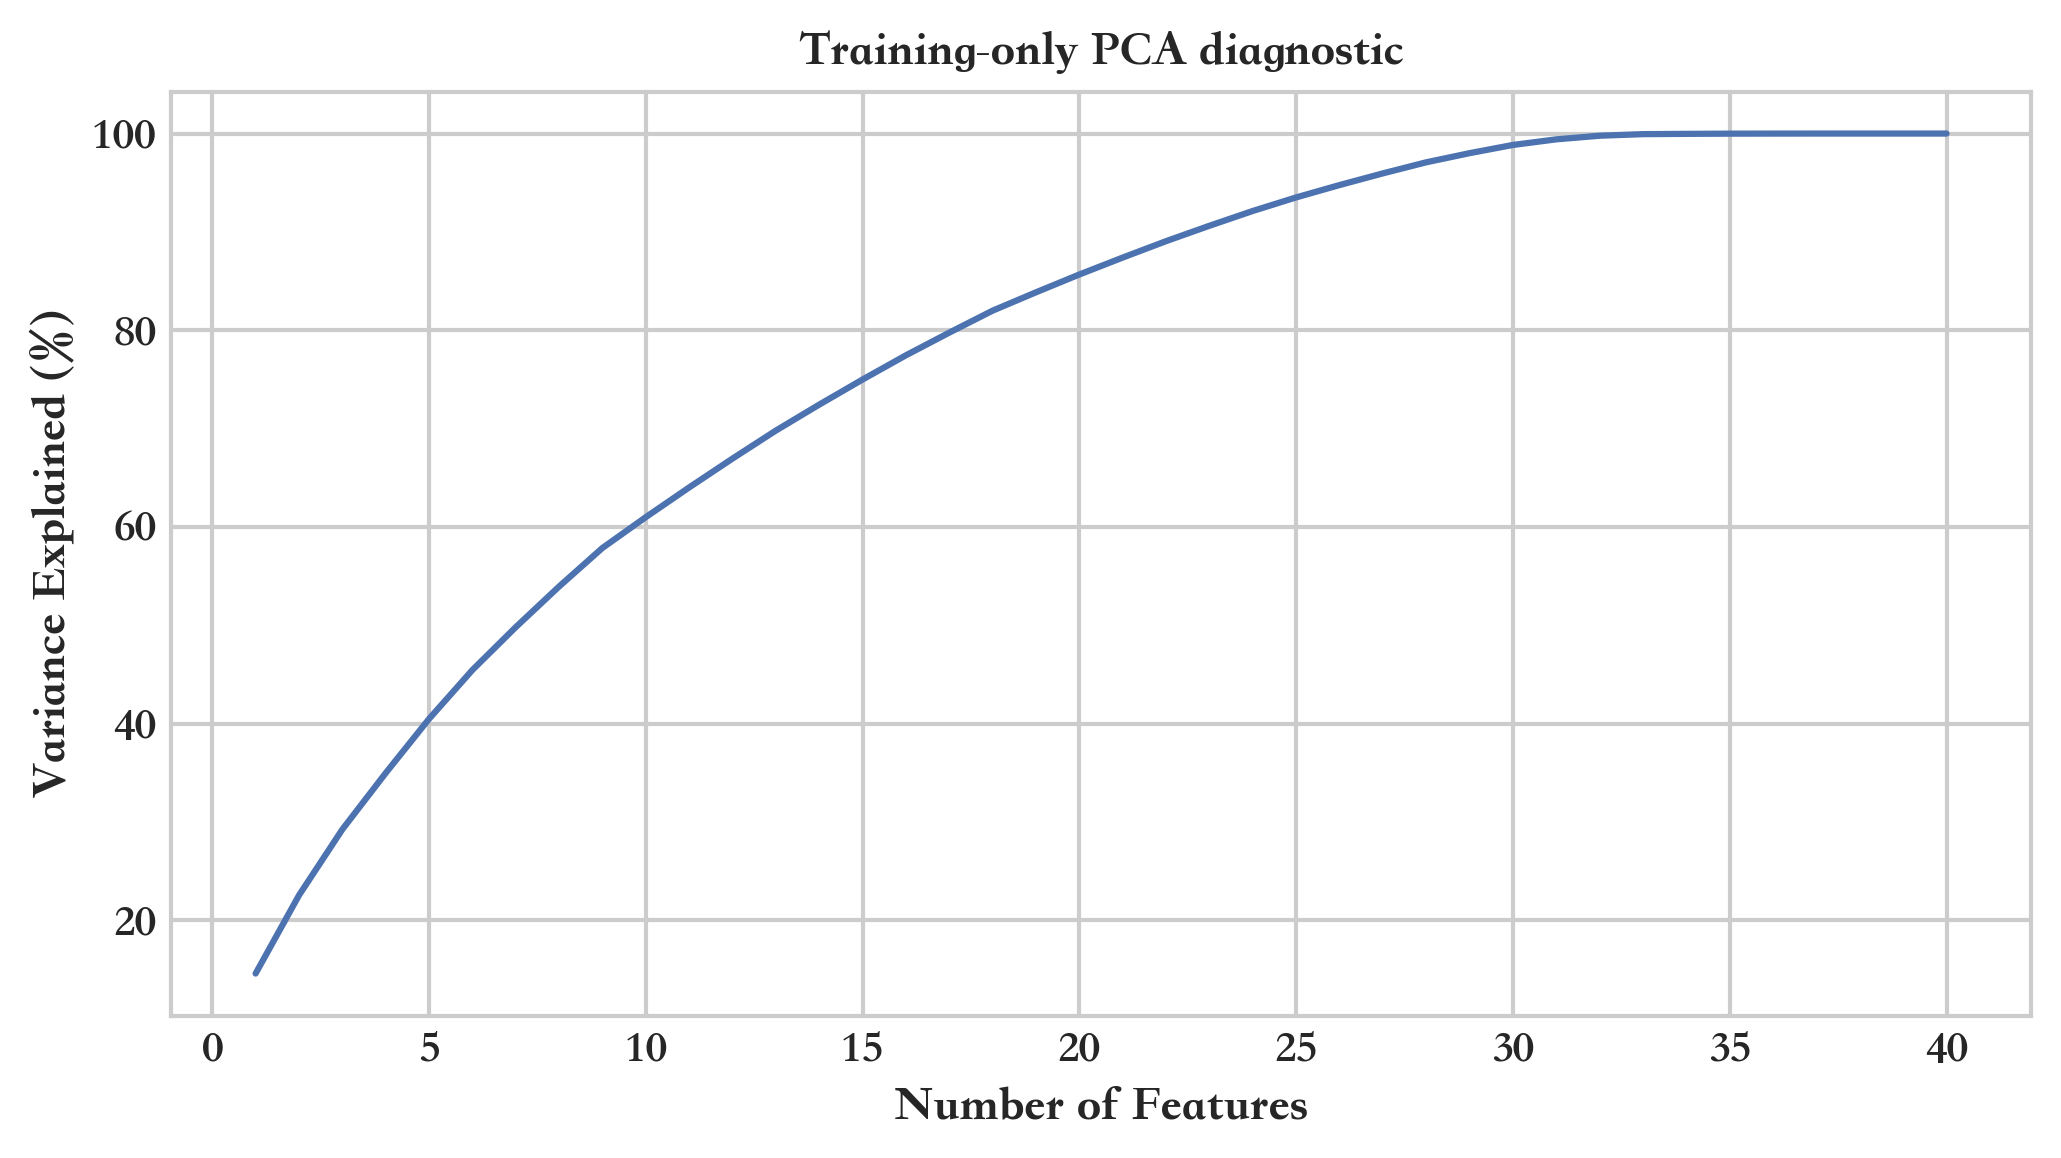

In [24]:
# PCA 图仅描述训练特征的方差，不代表保留同等比例的血糖预测信息。
pca_diagnostic = PCA(svd_solver="full").fit(z_score)
var = np.cumsum(pca_diagnostic.explained_variance_ratio_) * 100
plt.figure(figsize=(8, 4), dpi=300)
plt.plot(np.arange(1, len(var)+1), var)
plt.ylabel("Variance Explained (%)")
plt.xlabel("Number of Features")
plt.title("Training-only PCA diagnostic")
print("达到98%方差的成分数:", int(np.searchsorted(var, 98)+1))

In [25]:
# 不再提前把所有模型统一转换为 PCA 输入。
# 每种模型从原始 X_train_raw 开始，通过 select_representation 自行比较表示。
assert X_train_raw["年龄"].equals(train_raw_data["年龄"])
assert X_validation_raw["年龄"].equals(validation_raw_data["年龄"])
print("模型原始输入:", X_train_raw.shape, X_validation_raw.shape)

模型原始输入: (4649, 40) (1993, 40)


In [ ]:
# 本轮全程使用内存中的原始数据与独立 Pipeline，无旧中间文件依赖。

建模边界

所有训练折各自拟合列选择、缺失填补、缩放及可选 PCA。预处理消融与调参分数仅用于选型，有选择偏差；外层开发验证分数用于比较模型类别。

删列/PCA 的采用规则预先固定：相对“原始全特征”五折均不变差且平均误差更低，才有资格替换默认方案。这是保守的工程规则，不是统计显著性检验。每个消融报告包含同折差值与胜出折数。

按用户要求，最后对全部六个冻结后的算法进行 B 集外部对照；不根据 B 的排序回调参数，开发集冠军保留不变。

In [26]:
assert X_train_raw.index.equals(train_raw_data.index)
assert X_validation_raw.index.equals(validation_raw_data.index)
assert X_train_raw.columns.equals(X_validation_raw.columns)
print("完整训练特征/标签:", X_train_raw.shape, train_labels.shape)
print("开发验证特征/标签:", X_validation_raw.shape, validation_labels.shape)

完整训练特征/标签: (4649, 40) (4649,)
开发验证特征/标签: (1993, 40) (1993,)


岭回归预测基线（OLS 仍保留为前面的训练拟合诊断）

In [27]:
from sklearn.linear_model import Ridge

# 保留相关变量时用正则化控制病态矩阵；避免普通最小二乘在个别折中系数爆炸。
linear_pipeline = select_representation(Ridge(alpha=100.), "Ridge", "linear")
linear_pipeline.fit(X_train_raw, train_labels)
record_development("Ridge", linear_pipeline)


Ridge 选中预处理: ('raw', 'all')
representation   feature_set   CV_MSE  delta_MSE_vs_raw_all  fold_wins_vs_raw_all  eligible  selected
           raw           all 1.852585              0.000000                     0      True      True
           raw  no_hepatitis 1.850989             -0.001596                     3     False     False
           raw no_correlated 1.849604             -0.002982                     3     False     False
           raw   legacy_drop 1.847868             -0.004717                     4     False     False
           pca           all 1.861144              0.008559                     3     False     False
           pca  no_hepatitis 1.856754              0.004168                     3     False     False
           pca no_correlated 1.850856             -0.001729                     3     False     False
           pca   legacy_drop 1.847449             -0.005137                     3     False     False
{'model': 'Ridge', 'development_MSE': 2.28911528654854

array([5.75411879, 5.524419  , 6.08574213, ..., 6.54749452, 6.14834958,
       5.11212905], shape=(1993,))

神经网络：内部验证选表示和训练轮数，随后用完整训练集重拟合

标准化原始全特征与可选 PCA 均在内部训练子集拟合；内部验证只用于选二者及训练轮数。开发验证集不参与神经网络早停。网络结构沿用原方案，使用固定随机种子。

In [28]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, PReLU, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping

nn_fit_raw, nn_valid_raw, nn_fit_labels, nn_valid_labels = train_test_split(
    X_train_raw, train_labels, test_size=0.2, random_state=23
)
NN_MAX_EPOCHS = 100
NN_BATCH_SIZE = 32

def build_nn(n_features):
    tf.keras.utils.set_random_seed(23)
    nn = Sequential([
        Input(shape=(n_features,)),
        Dense(400, activation=PReLU()), Dropout(0.4),
        Dense(160, kernel_initializer="normal", activation=PReLU()), BatchNormalization(), Dropout(0.6),
        Dense(64, kernel_initializer="normal", activation=PReLU()), BatchNormalization(), Dropout(0.5),
        Dense(26, kernel_initializer="normal", activation=PReLU()), BatchNormalization(), Dropout(0.6),
        Dense(1, kernel_initializer="normal"),
    ])
    nn.compile(loss="mse", optimizer="adamax")
    return nn

print("神经网络内部训练/验证:", len(nn_fit_raw), len(nn_valid_raw))

神经网络内部训练/验证: 3719 930


In [29]:
nn_trials = []
for representation in ("raw", "pca"):
    nn_prep = make_preprocessor(representation, "all", "linear")
    nn_x_fit = nn_prep.fit_transform(nn_fit_raw)
    nn_x_valid = nn_prep.transform(nn_valid_raw)
    nn = build_nn(nn_x_fit.shape[1])
    history = nn.fit(
        nn_x_fit, nn_fit_labels, epochs=NN_MAX_EPOCHS, batch_size=NN_BATCH_SIZE,
        validation_data=(nn_x_valid, nn_valid_labels),
        callbacks=[EarlyStopping(monitor="val_loss", patience=12, restore_best_weights=True)], verbose=0,
    )
    internal_mse = mean_squared_error(nn_valid_labels, nn.predict(nn_x_valid, verbose=0).ravel())
    nn_trials.append({"representation": representation, "internal_MSE": float(internal_mse),
                      "best_epochs": int(np.argmin(history.history["val_loss"])+1),
                      "history": history.history})
# 同分优先 raw；全特征保留，不按真实血糖分组处理。
nn_choice = min(nn_trials, key=lambda item: item["internal_MSE"])
print(pd.DataFrame([{k:v for k,v in t.items() if k != "history"} for t in nn_trials]))
print("神经网络冻结配置:", {k:v for k,v in nn_choice.items() if k != "history"})

  representation  internal_MSE  best_epochs
0            raw      1.783111           81
1            pca      1.734386           85
神经网络冻结配置: {'representation': 'pca', 'internal_MSE': 1.7343861974402996, 'best_epochs': 85}


In [30]:
# 表示与轮数均已由内部验证确定，现在完整使用4649条训练记录。
nn_preprocessor = make_preprocessor(nn_choice["representation"], "all", "linear")
nn_train_features = nn_preprocessor.fit_transform(X_train_raw)
nn_model = build_nn(nn_train_features.shape[1])
myModel = nn_model.fit(nn_train_features, train_labels, epochs=nn_choice["best_epochs"],
                      batch_size=NN_BATCH_SIZE, verbose=0)
model_registry["NeuralNetwork"] = {"kind": "keras", "preprocessor": nn_preprocessor,
                                 "model": nn_model, "representation": nn_choice["representation"],
                                 "epochs": nn_choice["best_epochs"]}
print("完整训练集重拟合完成，轮数:", nn_choice["best_epochs"])

完整训练集重拟合完成，轮数: 85


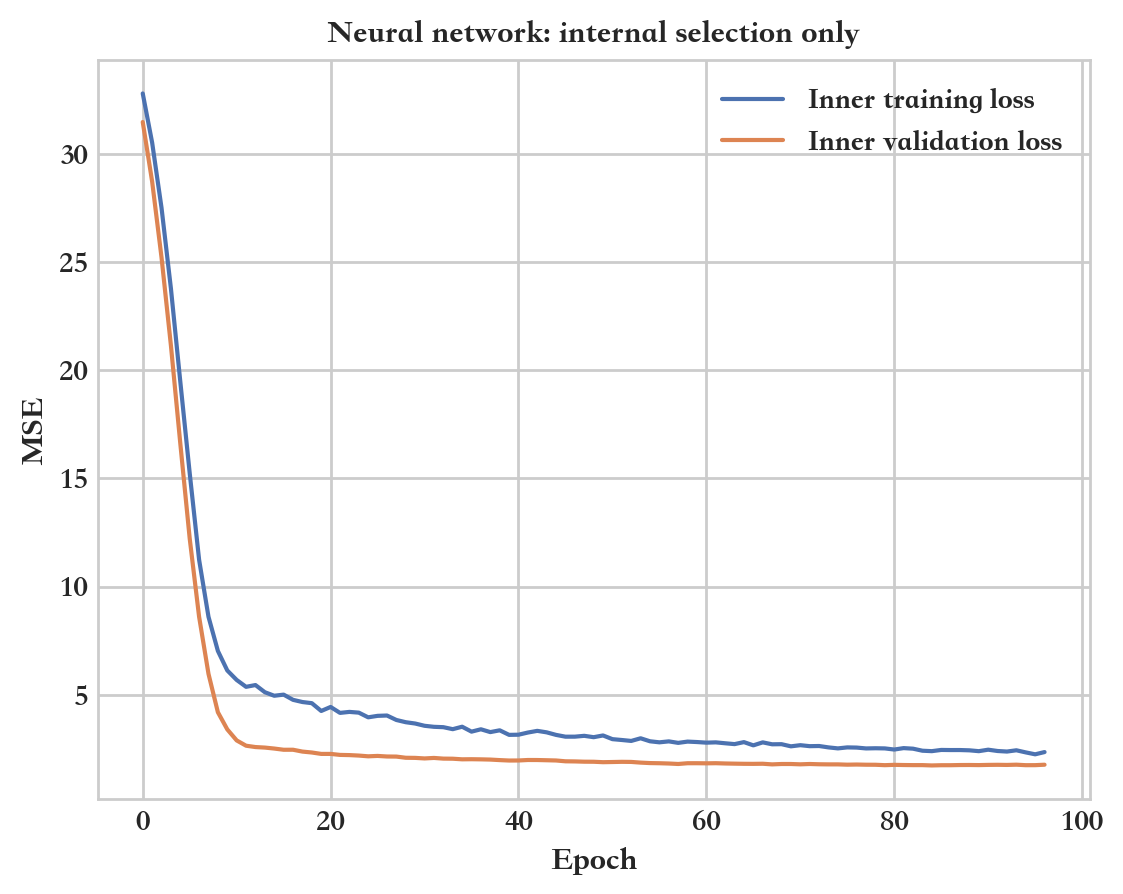

In [31]:
history = nn_choice["history"]
plt.figure(dpi=200)
plt.plot(history["loss"], label="Inner training loss")
plt.plot(history["val_loss"], label="Inner validation loss")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Neural network: internal selection only")
plt.legend()

In [32]:
nn_dev_prediction = nn_model.predict(nn_preprocessor.transform(X_validation_raw), verbose=0).ravel()
development_results.append({"model": "NeuralNetwork",
    "development_MSE": float(mean_squared_error(validation_labels, nn_dev_prediction)),
    "development_RMSE": float(np.sqrt(mean_squared_error(validation_labels, nn_dev_prediction))),
    "development_MAE": float(mean_absolute_error(validation_labels, nn_dev_prediction)),
    "development_R2": float(r2_score(validation_labels, nn_dev_prediction))})
print(development_results[-1])

{'model': 'NeuralNetwork', 'development_MSE': 2.388585792236966, 'development_RMSE': 1.5455050282147147, 'development_MAE': 0.7475518095511261, 'development_R2': 0.12826551614504667}


弱学习器 决策树 寻找最优参数组合（随机搜索）


In [33]:
from sklearn.tree import DecisionTreeRegressor

DeTree = DecisionTreeRegressor(criterion="squared_error", max_depth=5, min_samples_leaf=20,
                              random_state=30, splitter="random")
tree_pipeline = select_representation(DeTree, "DecisionTree", "tree")
param_dist = {"model__max_depth": [3, 4, 5, 6, 7],
              "model__min_samples_leaf": [10, 20, 40, 60],
              "model__min_samples_split": [2, 10, 20]}
random_search = RandomizedSearchCV(tree_pipeline, param_distributions=param_dist, n_iter=24,
    cv=cv, scoring="neg_mean_squared_error", random_state=23, n_jobs=SEARCH_N_JOBS)
random_search.fit(X_train_raw, train_labels)
print("决策树选型CV MSE:", -random_search.best_score_)
print(random_search.best_params_)

DecisionTree 选中预处理: ('raw', 'all')
representation   feature_set   CV_MSE  delta_MSE_vs_raw_all  fold_wins_vs_raw_all  eligible  selected
           raw           all 2.096819              0.000000                     0      True      True
           raw  no_hepatitis 2.054097             -0.042721                     3     False     False
           raw no_correlated 2.049593             -0.047226                     4     False     False
           raw   legacy_drop 2.097340              0.000521                     2     False     False
           pca           all 2.143096              0.046278                     1     False     False
           pca  no_hepatitis 2.070819             -0.025999                     3     False     False
           pca no_correlated 2.075253             -0.021565                     4     False     False
           pca   legacy_drop 2.047444             -0.049375                     4     False     False
决策树选型CV MSE: 2.026148753527685
{'model__min_sam

In [34]:
tree_model = random_search.best_estimator_
record_development("DecisionTree", tree_model)

{'model': 'DecisionTree', 'development_MSE': 2.5951759289624046, 'development_RMSE': 1.6109549742194549, 'development_MAE': 0.8296504628588666, 'development_R2': 0.052868707375111734}


array([5.56118603, 5.41860759, 6.09546539, ..., 6.57526316, 5.97388128,
       5.28327759], shape=(1993,))

AdaBoost


In [35]:
from sklearn.ensemble import AdaBoostRegressor

# 基础树预先固定，避免用同一CV已筛选的树把选择偏差带入下一层搜索。
adaboost_base = AdaBoostRegressor(
    estimator=DecisionTreeRegressor(max_depth=3, min_samples_leaf=20, random_state=23), random_state=32)
adaboost_pipeline = select_representation(adaboost_base, "AdaBoost", "tree")
param_dist = {"model__n_estimators": [100, 200, 300],
              "model__learning_rate": [0.005, 0.01, 0.03, 0.1],
              "model__loss": ["linear", "square", "exponential"]}
adaboost_search = RandomizedSearchCV(adaboost_pipeline, param_distributions=param_dist, n_iter=18,
    cv=cv, scoring="neg_mean_squared_error", n_jobs=SEARCH_N_JOBS, random_state=23)
adaboost_search.fit(X_train_raw, train_labels)
print(adaboost_search.best_params_)

AdaBoost 选中预处理: ('raw', 'all')
representation   feature_set   CV_MSE  delta_MSE_vs_raw_all  fold_wins_vs_raw_all  eligible  selected
           raw           all 4.586761              0.000000                     0      True      True
           raw  no_hepatitis 4.680862              0.094101                     3     False     False
           raw no_correlated 5.153151              0.566391                     1     False     False
           raw   legacy_drop 4.685833              0.099073                     3     False     False
           pca           all 4.918453              0.331692                     2     False     False
           pca  no_hepatitis 5.081084              0.494323                     1     False     False
           pca no_correlated 4.899678              0.312917                     2     False     False
           pca   legacy_drop 4.920459              0.333699                     2     False     False
{'model__n_estimators': 300, 'model__loss': 'expone

In [ ]:
adaboost = adaboost_search.best_estimator_
print("AdaBoost选型CV MSE:", -adaboost_search.best_score_)
record_development("AdaBoost", adaboost)

XGBoost


In [ ]:
from xgboost import XGBRegressor

xgb_base = XGBRegressor(objective="reg:squarederror", n_estimators=200, learning_rate=0.03,
                       max_depth=3, min_child_weight=20, reg_lambda=20,
                       random_state=23, n_jobs=1, tree_method="hist")
xgb_pipeline = select_representation(xgb_base, "XGBoost", "tree")
# 同时搜索轮数与结构，不再先固定一组结构、再扫描最终验证集轮数。
param_grid = {"model__n_estimators": [100, 200, 350],
              "model__learning_rate": [0.02, 0.05, 0.1],
              "model__max_depth": [2, 3, 4],
              "model__min_child_weight": [10, 30, 60],
              "model__reg_lambda": [10, 30, 60],
              "model__subsample": [0.8, 1.0],
              "model__colsample_bytree": [0.8, 1.0]}
xgb_search = RandomizedSearchCV(xgb_pipeline, param_distributions=param_grid, n_iter=24,
    cv=cv, scoring="neg_mean_squared_error", n_jobs=SEARCH_N_JOBS, random_state=23)
xgb_search.fit(X_train_raw, train_labels)
print("XGBoost选型CV MSE:", -xgb_search.best_score_)
print(xgb_search.best_params_)

In [ ]:
xgb_model = xgb_search.best_estimator_
record_development("XGBoost", xgb_model)

XGBoost 参数和轮数均由训练集内部 CV 选择。开发验证集用于模型类别比较；最终 B 集不进入这些搜索。CV 选型分数有选择偏差，不当作无偏测试成绩。

RandomForest


In [ ]:
from sklearn.ensemble import RandomForestRegressor

forest = RandomForestRegressor(n_estimators=200, max_depth=15, min_samples_leaf=12,
                               max_features=0.8, random_state=23, n_jobs=1)
forest_pipeline = select_representation(forest, "RandomForest", "tree")
forest_search = RandomizedSearchCV(forest_pipeline,
    param_distributions={"model__max_depth": [8, 15, None],
                         "model__min_samples_leaf": [7, 15, 30],
                         "model__max_features": [0.6, 0.8, 1.0]},
    n_iter=12, cv=cv, scoring="neg_mean_squared_error", random_state=23, n_jobs=SEARCH_N_JOBS)
forest_search.fit(X_train_raw, train_labels)
print("随机森林选型CV MSE:", -forest_search.best_score_)
print(forest_search.best_params_)

In [ ]:
forest_model = forest_search.best_estimator_
record_development("RandomForest", forest_model)

# 全部冻结算法的 B 集外部对照

按用户要求，固定六个算法已经选出的特征表示、特征集合、参数和神经网络轮数，不再执行任何搜索。各算法都用完整 train+A 的6642条记录重新拟合，再在同样的1000条B样本上比较。

开发集冠军仍由原1993条开发验证记录确定；B集表格仅用于观察排序是否一致，不据此重新选参数或更换开发集冠军。B此前已经被查看，此次又用于模型横向比较，因此这张表属于外部基准对照，不能再称为未触碰的最终测试成绩。

In [ ]:
development_summary = pd.DataFrame(development_results).sort_values("development_MSE").reset_index(drop=True)
assert len(development_summary) == len(model_registry) == 6
assert development_summary["model"].is_unique
champion_name = development_summary.iloc[0]["model"]
# 复制配置，防止外部评价时修改已选定的算法；不使用B标签决定任何参数。
frozen_registry = {}
for name, entry in model_registry.items():
    if entry["kind"] == "sklearn":
        frozen_registry[name] = {"kind": "sklearn", "pipeline": clone(entry["pipeline"])}
    else:
        frozen_registry[name] = {"kind": "keras", "representation": entry["representation"],
                                 "epochs": entry["epochs"]}
print("开发验证集比较（仅此表用于确定开发集冠军）:")
print(development_summary.to_string(index=False))
print("开发集冠军保持不变:", champion_name)
print("已冻结全部算法:", sorted(frozen_registry))

In [ ]:
def encode_model_features(frame):
    features = frame.drop(columns=["id", "体检日期", "血糖"], errors="ignore").copy()
    features["性别"] = features["性别"].map(sex_mapping)
    features["性别未知"] = features["性别"].isna().astype(float)
    return features.loc[:, X_train_raw.columns]

X_development_all = encode_model_features(raw_data)
y_development_all = raw_data["血糖"].to_numpy()
assert len(X_development_all) == 6642
external_models = {}
for name, entry in frozen_registry.items():
    if entry["kind"] == "sklearn":
        fitted = clone(entry["pipeline"]).fit(X_development_all, y_development_all)
        external_models[name] = {"kind": "sklearn", "model": fitted}
    else:
        prep = make_preprocessor(entry["representation"], "all", "linear")
        transformed = prep.fit_transform(X_development_all)
        fitted = build_nn(transformed.shape[1])
        fitted.fit(transformed, y_development_all, epochs=entry["epochs"],
                   batch_size=NN_BATCH_SIZE, verbose=0)
        external_models[name] = {"kind": "keras", "model": fitted, "preprocessor": prep}
    print(name, "冻结配置的完整开发数据重拟合完成")
assert set(external_models) == set(frozen_registry)

In [ ]:
# 所有算法均已冻结且重拟合完成，才读取B特征和答案。
b_features = pd.read_csv("./data/d_test_B_20180128.csv", encoding="utf-8")
assert b_features["id"].is_unique
assert set(raw_data["id"]).isdisjoint(b_features["id"])
X_external_b = encode_model_features(b_features)
b_labels = pd.read_csv("./data/d_answer_b_20180130.csv", header=None).iloc[:, 0].to_numpy()
assert len(b_labels) == len(b_features) == 1000
b_predictions = {}
external_rows = []
for name, entry in external_models.items():
    if entry["kind"] == "sklearn":
        prediction = entry["model"].predict(X_external_b)
    else:
        prediction = entry["model"].predict(entry["preprocessor"].transform(X_external_b), verbose=0).ravel()
    assert len(prediction) == len(b_labels) and np.isfinite(prediction).all()
    b_predictions[name] = prediction
    external_rows.append({"model": name, "B_MSE": float(mean_squared_error(b_labels, prediction)),
        "B_RMSE": float(np.sqrt(mean_squared_error(b_labels, prediction))),
        "B_MAE": float(mean_absolute_error(b_labels, prediction)),
        "B_R2": float(r2_score(b_labels, prediction))})
external_comparison = development_summary.merge(pd.DataFrame(external_rows), on="model", validate="one_to_one")
external_comparison["development_rank"] = external_comparison["development_MSE"].rank(method="min").astype(int)
external_comparison["B_rank"] = external_comparison["B_MSE"].rank(method="min").astype(int)
external_comparison = external_comparison.sort_values("B_MSE").reset_index(drop=True)
print("全部冻结算法的B集外部对照（MSE越小越好）:")
print(external_comparison[["model", "development_MSE", "development_rank", "B_MSE", "B_RMSE", "B_MAE", "B_R2", "B_rank"]].to_string(index=False))
print("开发集冠军:", champion_name)
print("本次B集MSE最低算法:", external_comparison.iloc[0]["model"])
print("MSE排序Spearman相关:", external_comparison["development_rank"].corr(external_comparison["B_rank"], method="spearman"))
# 仅保存比较结果，不用B排序回调模型或覆盖开发集冠军。
from pathlib import Path
b_output_dir = Path("review/external_b_comparison")
b_output_dir.mkdir(parents=True, exist_ok=True)
external_comparison.to_csv(b_output_dir / "comparison.csv", index=False)
pd.DataFrame({"id": b_features["id"], "actual": b_labels, **b_predictions}).to_csv(b_output_dir / "predictions.csv", index=False)

B 集配对误差差异（固定模型、固定训练样本下的描述性区间）

以 XGBoost 为参考，差值为“其他模型 MSE − XGBoost MSE”。正值代表 XGBoost 误差更小。区间只对当前B行重采样，未计入训练随机性、模型搜索、日期相关性及多重比较，不作为未来总体优劣的保证。

In [ ]:
rng = np.random.default_rng(23)
xgb_losses = (b_labels - b_predictions["XGBoost"]) ** 2
paired_rows = []
for name, prediction in b_predictions.items():
    if name == "XGBoost":
        continue
    delta = (b_labels - prediction) ** 2 - xgb_losses
    boot = np.array([rng.choice(delta, size=len(delta), replace=True).mean() for _ in range(3000)])
    paired_rows.append({"model": name, "MSE_minus_XGBoost": float(delta.mean()),
                       "conditional_95pct_low": float(np.quantile(boot, 0.025)),
                       "conditional_95pct_high": float(np.quantile(boot, 0.975))})
paired_comparison = pd.DataFrame(paired_rows)
print(paired_comparison.to_string(index=False))
paired_comparison.to_csv(b_output_dir / "paired_differences.csv", index=False)


## 顺序优化实验（2026-10-18）

已依次完成特征分组消融、120组联合随机搜索、简单融合、小型神经网络，并根据训练折外异常补充去乙肝网络与融合。仅用4649条训练记录的折外预测选择方案、参数和权重；冻结后统一评估开发1993条与B1000条。两套CV仍参与选择，并非嵌套CV；开发/B此前已查看，结果属于已知集合复核。

最终训练内部选出的方案：**XGBoost、LightGBM、Ridge、去乙肝64→32小网络各25%**。开发MSE从2.228808降至2.177243（下降2.31%），B从1.252744降至1.234296（下降1.47%）。B配对区间仍跨零，暂不能确认收益稳定。

| 阶段 | 训练CV均值 | 开发MSE | B_MSE |
| --- | --- | --- | --- |
| 当前XGBoost基线 | 1.806988 | 2.228808 | 1.252744 |
| 特征消融优胜 | 1.786509 | 2.218877 | 1.275351 |
| 联合搜索优胜 | 1.781861 | 2.236749 | 1.242601 |
| 简单融合优胜 | 1.762972 | 2.196540 | 1.245558 |
| 小型神经网络优胜 | 1.911642 | 2.260269 | 1.352561 |
| 补充：小网络融合 | 1.759568 | 2.177243 | 1.234296 |

特征工程和参数搜索并未各自在两个集合上同时变好；融合才在本轮两个集合上同时取得较低MSE。小网络单模型较弱，加入融合后有互补收益。预测已通过保存模型重新加载核验。

[完整实验展示](paper_experiments.ipynb) · [详细报告](review/sequential_experiments/report.md) · [指标CSV](review/sequential_experiments/stage_comparison.csv)


## 标准化与PCA对照实验（2026-10-20）

已完成10个冻结模型版本的四组处理，另加两个原生缺失参考，共42组配置、两套五折（420次训练折拟合），并统一评估开发1993条与B1000条。特征、模型参数、网络轮数不变；四格对照均使用相同的中位数填补和缺失指示，所有统计量仅拟合训练折。

**直接证据：** 树模型无需增加标准化，PCA无收益；Ridge标准化未显示明确收益，可保留现有处理；原大网络和去乙肝小网络标准化使训练CV MSE分别降低7.63%、20.33%。标准化后再加PCA，大网络差异不足0.05%，小网络变差约2.40%，均没有额外收益证据。

**流程替换与必要性不同：** 预设平均CV改善至少0.5%且赢7/10折才替换现有处理。故原大网络仍保留旧PCA，但不能把保留解释成PCA必需；本轮CV最低是仅标准化。唯一达到替换门槛的是LightGBM改为中位数填补＋缺失指示，仍不标准化、不做PCA。

| 模型 | 无标准化/无PCA | 仅标准化 | 仅PCA | 标准化后PCA |
| --- | --- | --- | --- | --- |
| Ridge | 1.848363 | 1.849622 | 1.944901 | 1.858446 |
| 决策树 | 2.033633 | 2.033633 | 2.087293 | 2.107930 |
| AdaBoost | 1.990995 | 1.990819 | 2.016526 | 2.051130 |
| 随机森林 | 1.851444 | 1.851883 | 1.942392 | 1.898163 |
| XGBoost原配置 | 1.806988 | 1.806988 | 1.939866 | 1.872072 |
| XGBoost优化配置 | 1.781861 | 1.781861 | 2.065189 | 1.841900 |
| LightGBM | 1.796304 | 1.805506 | 2.127522 | 1.875117 |
| HistGradientBoosting | 1.785411 | 1.784776 | 2.052189 | 1.884365 |
| 原大网络（87轮） | 2.089127 | 1.929678 | 1.983365 | 1.930533 |
| 去乙肝小网络（36轮） | 2.379670 | 1.895841 | 3.325018 | 1.941302 |

只改变建议预处理、不改各25%权重时，四模型融合开发MSE为2.174456（原2.177243），B为1.234823（原1.234296），未显示进一步稳定提升。旧模型和已有结果保留。开发/B此前已反复查看，属于已知集合复核；结论仅适用于本轮冻结参数与预算，不是算法普遍定律。

本轮大网络统一清理Keras状态后重新初始化，参考成绩与旧存档不是逐值相同，详见报告。其旧PReLU写法的权重加载流程已核验，无需修改base依赖。

[实验展示](paper_preprocessing_experiments.ipynb) · [完整报告](review/preprocessing_ablation/report.md) · [推荐对照CSV](review/preprocessing_ablation/recommendation_table.csv)
